# Is FX triangular arbitrage still executable? A microstructure-aware graph-arbitrage engine, tested out-of-sample

**MSc Financial Technology, Imperial College London, Data Structures & Algorithms capstone**

This notebook is the code deliverable; the written report is a separate document.
**Every number, table and figure below is computed when the notebook runs, from the files in `data/`.** No result is typed in by hand.
Sentences that quote numbers are generated from a results dictionary `R` (see `say()`), and the last cell writes `R` to
`data/derived/results.json`, so every number in the report can be traced to what this notebook produced.

**Hypothesis (fixed before any result was seen).**
*H0:* after paying the bid/ask spread on every leg, paying fees, and executing with the smallest delay this data can resolve (one 100 ms grid step),
a graph-based triangular/multi-leg FX arbitrage strategy has a mean net return per trade that is **not greater than zero out-of-sample**.
*Mechanism for why apparent arbitrage could be an illusion:* each currency pair's quote updates asynchronously, so a cycle can look profitable only because
one of its legs is stale. Market makers re-price that leg within milliseconds, and the bid/ask spread is charged on every leg.
*What would reject H0:* a positive out-of-sample mean net return per trade, with a day-block bootstrap p-value below 5 %, that also holds up under the latency, cost,
outlier and walk-forward checks below. A negative result is a legitimate outcome.

| Stage | What happens |
|---|---|
| 0 | Setup and **all assumptions in one place** |
| 1 | Universe, currency graph, cycle enumeration (k = 3, 4, 5 legs) |
| 2 | Data acquisition: reproducible snapshot of the raw archive, with manifest and checksums |
| 3 | Cleaning, with a count for every rule |
| 4 | Causal time alignment, look-ahead tests and a negative control |
| 5 | Vectorised cycle scanner over every sampled day |
| 6 | Reference Bellman–Ford engine, unit and property tests, cross-check against the scanner |
| 7 | Signal anatomy: mid-price illusion, stale quotes, cycle length |
| 8 | Strategy and backtest: tuning on the training period, evaluation on the test period |
| 9 | Latency decay and cost sensitivity |
| 10 | Walk-forward validation |
| 11 | Robustness and pitfall checks |
| 12 | Risk touchpoint |
| 13 | Efficiency touchpoint |
| 14 | Optional: order-book depth check on Dukascopy data (runs only if those files are present) |
| 15 | Export of results |

## Stage 0, Setup and assumptions

In [1]:
import os, re, json, math, time, hashlib, random, platform, warnings, shutil, subprocess
from pathlib import Path
from itertools import combinations
from contextlib import contextmanager
from datetime import datetime, timedelta, timezone

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=DeprecationWarning)
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.35,
                     "grid.linestyle": "--", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold"})

# ---- paths: notebook.ipynb sits next to the data/ folder ------------------------------------------
BASE_DIR = Path(os.environ.get("FX_BASE_DIR", Path.cwd())).resolve()
if not (BASE_DIR / "data").exists() and (BASE_DIR.parent / "data").exists():
    BASE_DIR = BASE_DIR.parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "kaggle"            # optional: the full raw archive (only needed to (re)build the snapshot)
SNAP_DIR = DATA_DIR / "snapshot"         # the submitted data snapshot: raw ticks for the sampled days
DERIVED_DIR = DATA_DIR / "derived"       # everything this notebook writes
FIG_DIR, TAB_DIR = DERIVED_DIR / "figures", DERIVED_DIR / "tables"
for d in (FIG_DIR, TAB_DIR): d.mkdir(parents=True, exist_ok=True)

# ---- results store, timing and display helpers ---------------------------------------------------
R = {}                      # every number quoted anywhere lives here and is exported at the end
STAGE_TIMES = {}            # wall-clock seconds per pipeline step (used by the efficiency touchpoint)
TRIALS = {"initial_tuning": 0, "walk_forward_retuning": 0}   # strategy configurations evaluated for SELECTION

@contextmanager
def stage(name):
    t0 = time.perf_counter()
    try: yield
    finally: STAGE_TIMES[name] = STAGE_TIMES.get(name, 0.0) + (time.perf_counter() - t0)

def say(text): display(Markdown(text))

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); plt.show(); plt.close(fig)

def save_table(df, name):
    (df if isinstance(df, pl.DataFrame) else pl.DataFrame(df)).write_csv(TAB_DIR / f"{name}.csv")

def isnum(x):
    return isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool) and math.isfinite(float(x))

def fmt(x, nd=2, plus=False):
    if not isnum(x): return "n/a"
    return f"{float(x):+,.{nd}f}" if plus else f"{float(x):,.{nd}f}"

def pct(x, nd=2, plus=False):
    return "n/a" if not isnum(x) else fmt(100 * float(x), nd, plus) + " %"

def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return jsonable(o.tolist())
    if isinstance(o, (bool, np.bool_)): return bool(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (float, np.floating)): return float(o) if math.isfinite(float(o)) else None
    if isinstance(o, datetime): return o.isoformat()
    if isinstance(o, pl.DataFrame): return jsonable(o.to_dicts())
    return o

def md_table(headers, rows):
    out = "| " + " | ".join(headers) + " |\n|" + "|".join(["---"] * len(headers)) + "|\n"
    return out + "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)

In [2]:
# =====================================================================================================
# ALL ASSUMPTIONS LIVE HERE. Nothing further down hard-codes a market parameter.
# =====================================================================================================
# -- Universe: the 20 pairs in the Kaggle archive (pairs that close no cycle are dropped automatically in Stage 1)
UNIVERSE = ["AUDJPY", "AUDNZD", "AUDUSD", "CADJPY", "CHFJPY", "EURCHF", "EURGBP", "EURJPY", "EURPLN", "EURUSD",
            "GBPJPY", "GBPUSD", "NZDUSD", "USDCAD", "USDCHF", "USDJPY", "USDMXN", "USDRUB", "USDTRY", "USDZAR"]
MAX_HOPS = 5                    # cycles with 3..MAX_HOPS legs are scanned

# -- Raw-data acquisition (optional; the submitted snapshot makes these unnecessary)
DOWNLOAD_RAW = False            # True: download the Kaggle archive with the kaggle CLI (needs your own ~/.kaggle/kaggle.json; never commit it)
KAGGLE_DATASET = "zahinawosaf/forex-tick-data"

# -- Snapshot (what is submitted in data/snapshot): N randomly chosen full trading days per month
SNAPSHOT_DAYS_PER_MONTH = 3     # more days = more statistical power but a bigger submission
SNAPSHOT_SEED = 2026            # days are random but reproducible (not hand-picked)
MIN_DAY_TICK_SHARE = 0.5        # a weekday qualifies if its tick count is >= 50 % of the month's median day (drops holidays / partial days)
REBUILD_SNAPSHOT = False        # True: rebuild data/snapshot from data/kaggle even if a snapshot exists

# -- Cleaning (causal rules only: a tick may be judged using EARLIER ticks, never later ones)
MAX_SPREAD_BPS = 200.0          # drop quotes with an absurd spread
MAX_JUMP_BPS = 100.0            # drop a tick whose mid is > 100 bps from the median mid of the previous 51 ticks
JUMP_WINDOW = 51

# -- Alignment
GRID_MS = 100                   # decision grid; the state labelled T only contains ticks with time < T (no look-ahead)
MAX_STATE_AGE_MS = 5_000        # a leg whose latest quote is older than this is treated as missing

# -- Execution and cost assumptions (each one is varied in a sensitivity analysis later)
FEE_BPS_PER_LEG = 0.10          # taker commission per leg, in bps of notional
FEE_GRID_BPS = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
LATENCY_BASE_MS = 100           # signal-to-fill delay: one grid step, the smallest delay this data can resolve (optimistic)
LATENCY_GRID_MS = [0, 100, 200, 300, 500, 1000, 2000]   # 0 ms = fill at the signal-time quotes; not achievable, shown as the "paper" result
COOLDOWN_MS = 1_000             # after a trade, no new trade for this long (one arbitrage at a time, across all cycles)
NOTIONAL_USD = 1_000_000        # notional per leg of each trade
CAPITAL_USD = 5_000_000         # capital base used to turn PnL into a return (changes % return and drawdown, not Sharpe)
STRESS_SPREAD_MULTS = [2.0, 3.0]  # liquidity-crunch scenario: execution spreads widened by these factors

# -- Strategy parameters, tuned on the training period only
THETA_GRID_BPS = [0.0, 0.1, 0.25, 0.5, 1.0]        # minimum net edge at signal time
AGE_GRID_MS = [100, 250, 500, 1000, 2000]          # maximum age of the stalest leg at signal time
MIN_TRADES_FOR_SELECTION = 30

# -- Validation design (fixed before seeing results)
TRAIN_FRACTION = 0.60           # first 60 % of months = training; the remaining months are not touched until the configuration is frozen
WF_MIN_TRAIN_FRACTION = 0.40    # walk-forward: size of the first expanding training window
WF_TEST_BLOCK_MONTHS = 3
N_BOOT, BOOT_SEED = 2_000, 12345

# -- Optional Dukascopy order-book depth check (Stage 14); runs only if Dukascopy files are in data/ or data/dukascopy/
FETCH_DUKASCOPY = False         # True: download one hour of Dukascopy ticks (public, no credentials) before Stage 14
DUKA_FETCH_DATE, DUKA_FETCH_HOUR = "2026-10-14", 13
DUKA_PAIRS = ["EURUSD", "GBPUSD", "EURGBP"]
DEPTH_SLIP_BPS_PER_EXCESS = 0.5 # slippage: +0.5 bps for each multiple of top-of-book size that the order exceeds
DEPTH_PRUNE_FRACTION = 0.1      # a leg is untradeable if top-of-book size < 10 % of the order size
# Dukascopy reports top-of-book volume in millions of base currency; the order size is NOTIONAL_USD / 1e6 million.

# -- Memory control only (does not change results)
CHUNK_ROWS = 40_000

assert LATENCY_BASE_MS in LATENCY_GRID_MS, "LATENCY_BASE_MS must be one of LATENCY_GRID_MS"
assert all(L % GRID_MS == 0 for L in LATENCY_GRID_MS), "latencies must be multiples of GRID_MS"
assert FEE_BPS_PER_LEG in FEE_GRID_BPS
say(f"**Environment:** Python {platform.python_version()}, polars {pl.__version__}, numpy {np.__version__}.  \n"
    f"**Project folder:** `{BASE_DIR}`")

**Environment:** Python 3.14.7, polars 2.0.0, numpy 2.5.4.  
**Project folder:** `/Users/shrey/Developer/python-capstone`

## Stage 1, Universe, currency graph and cycle enumeration
Each quoted pair `BASEQUOTE` gives two directed edges: **sell the base at the bid** (`direct`, rate = bid) and **buy the base at the ask** (`inverse`, rate = 1/ask).
Because the two directions use different prices, the spread is built into the graph, and a round trip on a single pair always loses money.
A cycle is profitable when the product of its edge rates exceeds 1, which is the same as the sum of `-ln(rate)` being negative (a **negative cycle**).

In [3]:
def build_adjacency(pairs):
    adj = {}
    for p in pairs:
        b, q = p[:3], p[3:]
        adj.setdefault(b, []).append((q, p, "direct"))    # b -> q : sell base at BID
        adj.setdefault(q, []).append((b, p, "inverse"))   # q -> b : buy base at ASK (rate 1/ask)
    return adj

def enumerate_cycles(adj, k):
    """All simple directed cycles with exactly k edges. Each cycle is listed once per direction,
    starting from its alphabetically smallest currency. Depth-first search over paths of length <= k."""
    out = []
    for s in sorted(adj):
        def dfs(path, legs):
            u = path[-1]
            if len(legs) == k - 1:
                for v, p, d in adj[u]:
                    if v == s: out.append((path + [s], legs + [(p, d)]))
                return
            for v, p, d in adj[u]:
                if v > s and v not in path: dfs(path + [v], legs + [(p, d)])
        dfs([s], [])
    return out

ADJ_ALL = build_adjacency(UNIVERSE)
CYCLES = []
for k in range(3, MAX_HOPS + 1):
    for path, legs in enumerate_cycles(ADJ_ALL, k):
        CYCLES.append({"id": len(CYCLES), "k": k, "name": ">".join(path), "ccy": path[:-1], "legs": legs})

USED_PAIRS = sorted({p for c in CYCLES for p, _ in c["legs"]})
DROPPED_PAIRS = sorted(set(UNIVERSE) - set(USED_PAIRS))
CCY = sorted({p[:3] for p in USED_PAIRS} | {p[3:] for p in USED_PAIRS})
CYC_K = np.array([c["k"] for c in CYCLES]); N_CYC = len(CYCLES)
assert N_CYC > 0, "the universe contains no cycle"

cycle_counts = pl.DataFrame({"k": CYC_K}).group_by("k").len().rename({"len": "n_cycles"}).sort("k")
R["universe"] = {"pairs_in_universe": len(UNIVERSE), "pairs_used": USED_PAIRS, "pairs_dropped_no_cycle": DROPPED_PAIRS,
                 "currencies": CCY, "n_cycles_total": N_CYC,
                 "n_cycles_by_k": {int(r["k"]): int(r["n_cycles"]) for r in cycle_counts.to_dicts()}}
display(cycle_counts)
by_k_txt = ", ".join(f"{r['n_cycles']} with {r['k']} legs" for r in cycle_counts.to_dicts())
say(f"The universe has **{len(UNIVERSE)}** pairs. **{len(USED_PAIRS)}** of them lie on at least one cycle of up to {MAX_HOPS} legs "
    f"(dropped because they close no cycle: {', '.join(DROPPED_PAIRS) or 'none'}). "
    f"The graph has **{len(CCY)}** currencies and **{N_CYC}** directed cycles ({by_k_txt}).")

k,n_cycles
i64,u32
3,20
4,34
5,36


The universe has **20** pairs. **15** of them lie on at least one cycle of up to 5 legs (dropped because they close no cycle: EURPLN, USDMXN, USDRUB, USDTRY, USDZAR). The graph has **8** currencies and **90** directed cycles (20 with 3 legs, 34 with 4 legs, 36 with 5 legs).

## Stage 2, Data acquisition: a reproducible snapshot
**Source.** A public Kaggle archive of FX tick data (one folder per month, one headerless CSV per pair: `pair, timestamp, bid, ask`).
It can be downloaded with the Kaggle CLI (`DOWNLOAD_RAW = True`, using your own credentials, which are never stored in the project) or manually into `data/kaggle/`.

**Snapshot.** The full archive (several GB) is too large to submit. `build_snapshot()` keeps **every raw tick** of the universe pairs for a random, seeded sample
of full trading days per month, writes them to compressed parquet and records `manifest.json` (source files, row counts, chosen days, SHA-256 of every file).
Anyone with the raw archive can rebuild it; anyone without it can run the whole notebook from `data/snapshot/` alone.

Using the existing snapshot (created 2026-10-23T00:35:14+00:00 UTC).


**Snapshot:** 29 months (2020-04 to 2022-08), **87 sampled trading days**, 435 parquet files, **247,124,537 raw ticks**, 1,001.8 MB on disk. All 435 SHA-256 checksums match the manifest. Months with a missing pair: 0.

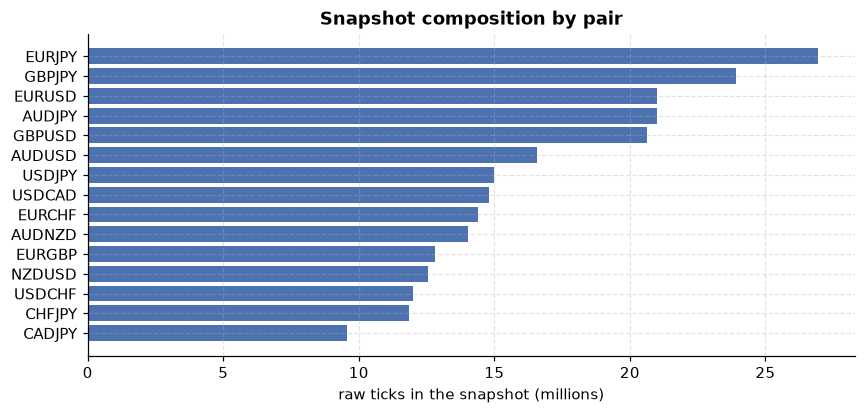

In [4]:
SNAP_TICKS = SNAP_DIR / "ticks"
MANIFEST_PATH = SNAP_DIR / "manifest.json"

def download_raw_archive():
    """Optional automated download (public dataset; needs the user's own Kaggle API token in ~/.kaggle)."""
    if shutil.which("kaggle") is None:
        raise RuntimeError("kaggle CLI not found: `pip install kaggle`, put your API token in ~/.kaggle/kaggle.json, or download manually into data/kaggle/")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_DATASET, "-p", str(RAW_DIR), "--unzip"], check=True)

def month_key_from_folder(name):
    for f in ("%B%Y", "%B %Y", "%b%Y", "%Y-%m", "%Y_%m"):
        try:
            d = datetime.strptime(name, f); return f"{d.year}-{d.month:02d}"
        except ValueError:
            pass
    return None

def find_pair_csvs(month_dir, pairs):
    """Maps each pair to its CSV inside a month folder by looking for the 6-letter pair code in the file name."""
    found = {}
    for p in sorted(month_dir.rglob("*")):
        if p.is_file() and p.suffix.lower() == ".csv":
            letters = re.sub(r"[^A-Z]", "", p.stem.upper())
            hits = sorted((letters.find(c), c) for c in pairs if c in letters)
            if hits and hits[0][1] not in found: found[hits[0][1]] = p
    return found

def scan_raw_csv(path):
    """Headerless CSV: PAIR, 'YYYYMMDD HH:MM:SS.mmm', BID, ASK -> lazy frame (timestamp kept as text for now)."""
    lf = pl.scan_csv(path, has_header=False, infer_schema_length=0)
    cols = lf.collect_schema().names()
    return lf.select([pl.col(cols[1]).str.strip_chars().str.slice(0, 21).alias("ts_raw"),
                      pl.col(cols[2]).cast(pl.Float64, strict=False).alias("bid"),
                      pl.col(cols[3]).cast(pl.Float64, strict=False).alias("ask")])

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            blk = f.read(chunk)
            if not blk: break
            h.update(blk)
    return h.hexdigest()

def choose_days(pair_csvs, month_key):
    ref = "EURUSD" if "EURUSD" in pair_csvs else sorted(pair_csvs)[0]
    cnt = (scan_raw_csv(pair_csvs[ref]).select(pl.col("ts_raw").str.slice(0, 8).alias("d"))
           .filter(pl.col("d").str.contains(r"^\d{8}$")).group_by("d").len().collect().sort("d"))
    cutoff = MIN_DAY_TICK_SHARE * float(cnt["len"].median())
    ok = [d for d, n in zip(cnt["d"].to_list(), cnt["len"].to_list())
          if n >= cutoff and datetime.strptime(d, "%Y%m%d").weekday() < 5]
    rng = random.Random(f"{SNAPSHOT_SEED}-{month_key}")
    return sorted(rng.sample(ok, min(SNAPSHOT_DAYS_PER_MONTH, len(ok)))), ref, int(cnt.height), len(ok)

def build_snapshot():
    if SNAP_DIR.exists(): shutil.rmtree(SNAP_DIR)
    SNAP_TICKS.mkdir(parents=True, exist_ok=True)
    dirs = [p for p in RAW_DIR.iterdir() if p.is_dir()]
    folders = sorted((month_key_from_folder(p.name), p) for p in dirs if month_key_from_folder(p.name))
    if not folders:
        raise FileNotFoundError(f"No month folders recognised in {RAW_DIR} (found: {[p.name for p in dirs][:10]})")
    files, months = [], {}
    for mk, mdir in folders:
        pcsv = find_pair_csvs(mdir, USED_PAIRS)
        missing = sorted(set(USED_PAIRS) - set(pcsv))
        if len(pcsv) < 3:
            print(f"[{mk}] skipped: only {len(pcsv)} universe pairs found"); continue
        days, ref, n_seen, n_ok = choose_days(pcsv, mk)
        months[mk] = {"folder": mdir.name, "days": days, "reference_pair_for_day_selection": ref,
                      "days_seen_in_reference_file": n_seen, "days_qualifying": n_ok, "pairs_missing": missing}
        (SNAP_TICKS / mk).mkdir(exist_ok=True)
        for pair, path in sorted(pcsv.items()):
            df = (scan_raw_csv(path).filter(pl.col("ts_raw").str.slice(0, 8).is_in(days))
                  .with_columns(pl.col("ts_raw").str.to_datetime("%Y%m%d %H:%M:%S%.f", strict=False, time_unit="us").alias("time"))
                  .select(["time", "bid", "ask"]).collect())
            n_bad = int(df["time"].null_count())
            df = df.drop_nulls("time").sort("time", maintain_order=True)
            out = SNAP_TICKS / mk / f"{pair}.parquet"
            df.write_parquet(out, compression="zstd", compression_level=10)
            files.append({"month": mk, "pair": pair, "path": out.relative_to(SNAP_DIR).as_posix(), "rows": int(df.height),
                          "rows_unparseable_time_dropped": n_bad, "bytes": out.stat().st_size, "sha256": sha256_file(out),
                          "source_file": path.relative_to(RAW_DIR).as_posix(), "source_bytes": path.stat().st_size})
        print(f"[{mk}] days {days} | {len(pcsv)} pairs" + (f" | missing {missing}" if missing else ""), flush=True)
    manifest = {"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "polars": pl.__version__,
                "params": {"days_per_month": SNAPSHOT_DAYS_PER_MONTH, "seed": SNAPSHOT_SEED, "min_day_tick_share": MIN_DAY_TICK_SHARE,
                           "pairs": USED_PAIRS, "source": f"Kaggle dataset {KAGGLE_DATASET} (headerless CSV: pair, timestamp, bid, ask)"},
                "months": months, "files": files}
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=1))
    return manifest

with stage("2. snapshot: build or load + verify checksums"):
    if DOWNLOAD_RAW: download_raw_archive()
    if REBUILD_SNAPSHOT or not MANIFEST_PATH.exists():
        if not RAW_DIR.exists():
            raise FileNotFoundError(f"No snapshot at {SNAP_DIR} and no raw archive at {RAW_DIR}. Put the monthly folders in data/kaggle/ "
                                    f"(or put the submitted data/snapshot/ folder next to this notebook).")
        print("Building the snapshot from the raw archive ..."); MANIFEST = build_snapshot()
    else:
        MANIFEST = json.loads(MANIFEST_PATH.read_text()); print(f"Using the existing snapshot (created {MANIFEST['created_utc']} UTC).")
    bad = [f["path"] for f in MANIFEST["files"] if not (SNAP_DIR / f["path"]).exists() or sha256_file(SNAP_DIR / f["path"]) != f["sha256"]]
    assert not bad, f"Snapshot integrity check failed for: {bad[:5]}"
    if set(MANIFEST["params"]["pairs"]) != set(USED_PAIRS):
        warnings.warn("The snapshot's pair list differs from USED_PAIRS; only pairs present in both are used.")

MONTHS = sorted(MANIFEST["months"])
SAMPLED_DAYS = [(mk, d) for mk in MONTHS for d in MANIFEST["months"][mk]["days"]]   # chronological
DAY_TABLE = pl.DataFrame({"day_idx": list(range(len(SAMPLED_DAYS))), "month": [m for m, _ in SAMPLED_DAYS],
                          "day": [d for _, d in SAMPLED_DAYS]}, schema={"day_idx": pl.Int32, "month": pl.Utf8, "day": pl.Utf8})
snap_df = pl.DataFrame(MANIFEST["files"])
pair_rows = snap_df.group_by("pair").agg(pl.col("rows").sum().alias("ticks")).sort("ticks", descending=True)
R["snapshot"] = {"created_utc": MANIFEST["created_utc"], "source": MANIFEST["params"]["source"], "n_months": len(MONTHS),
                 "first_month": MONTHS[0], "last_month": MONTHS[-1], "n_sampled_days": len(SAMPLED_DAYS),
                 "days_per_month_param": MANIFEST["params"]["days_per_month"], "n_files": snap_df.height,
                 "total_ticks": int(snap_df["rows"].sum()), "size_mb": float(snap_df["bytes"].sum() / 1e6),
                 "raw_source_mb_of_these_files": float(snap_df["source_bytes"].sum() / 1e6),
                 "unparseable_rows_dropped": int(snap_df["rows_unparseable_time_dropped"].sum()),
                 "months_with_missing_pairs": {m: v["pairs_missing"] for m, v in MANIFEST["months"].items() if v["pairs_missing"]},
                 "months_with_fewer_days_than_requested": {m: len(v["days"]) for m, v in MANIFEST["months"].items()
                                                           if len(v["days"]) < MANIFEST["params"]["days_per_month"]}}
say(f"**Snapshot:** {len(MONTHS)} months ({MONTHS[0]} to {MONTHS[-1]}), **{len(SAMPLED_DAYS)} sampled trading days**, "
    f"{snap_df.height} parquet files, **{R['snapshot']['total_ticks']:,} raw ticks**, {R['snapshot']['size_mb']:,.1f} MB on disk. "
    f"All {snap_df.height} SHA-256 checksums match the manifest. "
    f"Months with a missing pair: {len(R['snapshot']['months_with_missing_pairs'])}.")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(pair_rows["pair"].to_list()[::-1], (pair_rows["ticks"] / 1e6).to_list()[::-1], color="#4C72B0")
ax.set_xlabel("raw ticks in the snapshot (millions)"); ax.set_title("Snapshot composition by pair")
savefig(fig, "fig_snapshot_composition")

## Stage 3, Cleaning (with a count for every rule)
The rules are **causal**: a tick may only be rejected using information from *earlier* ticks, because a live system could not see later ones.
(Removing a spike because the *next* tick reverts would quietly use the future.) Every rejected row is counted per rule, per pair and per day;
nothing is dropped silently.

In [5]:
def _roll_median(expr, window):
    try:    return expr.rolling_median(window_size=window, min_samples=max(5, window // 5))
    except TypeError: return expr.rolling_median(window_size=window, min_periods=max(5, window // 5))   # older polars

CLEAN_RULES = ["null_value", "non_positive", "crossed_quote", "duplicate_timestamp", "wide_spread", "price_jump"]

def clean_ticks(df):
    """df: columns time, bid, ask (+ optional extra columns). Returns (clean_df, counts per rule)."""
    a = {"raw": df.height}; n = df.height
    df = df.drop_nulls(["time", "bid", "ask"]).filter(pl.col("bid").is_finite() & pl.col("ask").is_finite())
    a["null_value"] = n - df.height; n = df.height
    df = df.filter((pl.col("bid") > 0) & (pl.col("ask") > 0));                 a["non_positive"] = n - df.height; n = df.height
    df = df.filter(pl.col("ask") >= pl.col("bid"));                            a["crossed_quote"] = n - df.height; n = df.height
    df = df.sort("time", maintain_order=True).unique(subset=["time"], keep="last", maintain_order=True)   # same timestamp: keep the last quote
    a["duplicate_timestamp"] = n - df.height; n = df.height
    df = df.with_columns(((pl.col("bid") + pl.col("ask")) / 2).alias("_mid"))
    df = df.filter((pl.col("ask") - pl.col("bid")) / pl.col("_mid") * 1e4 <= MAX_SPREAD_BPS); a["wide_spread"] = n - df.height; n = df.height
    ref = _roll_median(pl.col("_mid").shift(1), JUMP_WINDOW)                    # median of PREVIOUS ticks only
    jump = ((pl.col("_mid") / ref - 1.0).abs() * 1e4 > MAX_JUMP_BPS).fill_null(False)
    df = df.filter(~jump).drop("_mid");                                         a["price_jump"] = n - df.height
    a["kept"] = df.height
    return df, a

def read_month_pair(month, pair):
    p = SNAP_TICKS / month / f"{pair}.parquet"
    return pl.read_parquet(p) if p.exists() else None

def load_day_ticks(month, day_str, pairs=USED_PAIRS, month_cache=None):
    """Returns ({pair: clean ticks}, [count rows]) for one sampled day."""
    day = datetime.strptime(day_str, "%Y%m%d").date()
    ticks, audit = {}, []
    for pair in pairs:
        full = month_cache.get(pair) if month_cache is not None else read_month_pair(month, pair)
        if full is None: continue
        part = full.filter(pl.col("time").dt.date() == day)
        if part.height == 0: continue
        clean, a = clean_ticks(part)
        if clean.height: ticks[pair] = clean
        audit.append({"month": month, "day": day_str, "pair": pair, **a})
    return ticks, audit

# demonstration on one sampled day (the totals over every day are produced by the scan in Stage 5)
with stage("3. cleaning (one demo day)"):
    _m, _d = SAMPLED_DAYS[len(SAMPLED_DAYS) // 2]
    _t, _a = load_day_ticks(_m, _d)
demo_audit = pl.DataFrame(_a).with_columns((pl.col("raw") - pl.col("kept")).alias("removed"),
                                           ((pl.col("raw") - pl.col("kept")) / pl.col("raw") * 100).round(4).alias("removed_%"))
say(f"**Cleaning on one sampled day ({_d}).** Totals over all days follow after the scan.")
display(demo_audit.drop(["month", "day"]))

**Cleaning on one sampled day (20210621).** Totals over all days follow after the scan.

pair,raw,null_value,non_positive,crossed_quote,duplicate_timestamp,wide_spread,price_jump,kept,removed,removed_%
str,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64
"""AUDJPY""",134230,0,0,0,54,0,0,134176,54,0.0402
"""AUDNZD""",75064,0,0,0,26,0,0,75038,26,0.0346
"""AUDUSD""",225433,0,0,0,278,0,0,225155,278,0.1233
"""CADJPY""",85830,0,0,0,13,0,0,85817,13,0.0151
"""CHFJPY""",99327,0,0,0,25,0,0,99302,25,0.0252
"""EURCHF""",64809,0,0,0,31,0,0,64778,31,0.0478
"""EURGBP""",75456,0,0,0,19,0,0,75437,19,0.0252
"""EURJPY""",157986,0,0,0,139,0,0,157847,139,0.088
"""EURUSD""",243500,0,0,0,292,0,0,243208,292,0.1199


## Stage 4, Causal time alignment
Pairs tick at different, irregular times. The **decision grid** has `GRID_MS` steps, and each 100 ms bin is labelled by its **right edge** `T`.
The state at `T` holds, for each pair, the last tick with `time < T` (backward as-of join). A decision taken at `T` therefore uses nothing that happened at or after `T`.
Each leg also carries the timestamp of its last tick, so the **age of every quote** is known: a cycle is only as fresh as its stalest leg.

Labelling a bin by its *left* edge would let a decision at `T` see ticks up to `T + 100 ms`, a classic look-ahead bug. It is built below only as a
**negative control**, to show that the look-ahead test really detects that bug.

In [6]:
def build_day_state(ticks, grid_ms=GRID_MS, label="right", value_cols=("bid", "ask"), max_age_ms=MAX_STATE_AGE_MS):
    """ticks: {pair: DataFrame(time, bid, ask, ...)} -> DataFrame: time, <pair>_<col>..., <pair>_ts (time of that pair's last tick)."""
    g = f"{grid_ms}ms"
    shift = pl.duration(milliseconds=grid_ms) if label == "right" else pl.duration(milliseconds=0)
    binned = {}
    for p, df in ticks.items():
        if df.height == 0: continue
        binned[p] = (df.with_columns((pl.col("time").dt.truncate(g) + shift).alias("grid"))
                       .group_by("grid", maintain_order=True)
                       .agg([pl.col("time").last().alias("ts")] + [pl.col(c).last() for c in value_cols])
                       .rename({c: f"{p}_{c}" for c in value_cols} | {"ts": f"{p}_ts"}))
    if not binned: return pl.DataFrame()
    master = pl.concat([b.select("grid") for b in binned.values()]).unique().sort("grid")
    tol = timedelta(milliseconds=max_age_ms + grid_ms)
    for p, b in binned.items():
        master = master.join_asof(b, on="grid", strategy="backward", tolerance=tol)
    return master.rename({"grid": "time"})

def causality_invariant(state, pairs):
    """Smallest (decision time - time of the leg's last tick) over all states and legs, in microseconds. Must be >= 0."""
    vals = []
    for p in pairs:
        if f"{p}_ts" in state.columns:
            v = state.select((pl.col("time") - pl.col(f"{p}_ts")).dt.total_microseconds().min()).item()
            if v is not None: vals.append(v)
    return min(vals) if vals else None

def truncation_test(ticks, label, n_cutoffs=40, window_s=120, seed=7):
    """Rebuild the state from ticks <= c only and compare every state with time <= c against the full build.
    A causal pipeline gives IDENTICAL states; a difference means a state at time <= c used information from after c."""
    rng = np.random.default_rng(seed)
    t_all = pl.concat([d.select("time") for d in ticks.values()]).sort("time")["time"]
    t0 = t_all[int(len(t_all) * 0.4)]; t1 = t0 + timedelta(seconds=window_s)
    sl = {p: d.filter((pl.col("time") >= t0) & (pl.col("time") <= t1)) for p, d in ticks.items()}
    full = build_day_state(sl, label=label)
    n_bad = 0
    for off in rng.integers(int(0.1 * window_s * 1e6), int(0.9 * window_s * 1e6), size=n_cutoffs):
        c = t0 + timedelta(microseconds=int(off))
        part = build_day_state({p: d.filter(pl.col("time") <= c) for p, d in sl.items()}, label=label)
        # a pair with no tick yet before c has no columns in the truncated build: that means "no information", i.e. nulls
        part = part.with_columns([pl.lit(None, dtype=full.schema[col]).alias(col) for col in full.columns if col not in part.columns]).select(full.columns)
        a = full.filter(pl.col("time") <= c).sort("time"); b = part.filter(pl.col("time") <= c).sort("time")
        if not (a.height == b.height and a.equals(b)): n_bad += 1
    return n_bad, n_cutoffs

with stage("4. alignment (demo day) + look-ahead tests"):
    _state = build_day_state(_t)
    inv_min_us = causality_invariant(_state, USED_PAIRS)
    bad_right, n_cut = truncation_test(_t, "right")
    bad_left, _ = truncation_test(_t, "left")
    inv_min_us_left = causality_invariant(build_day_state(_t, label="left"), USED_PAIRS)

R["lookahead_tests"] = {"demo_day": _d, "n_states_demo_day": int(_state.height), "truncation_cutoffs": n_cut,
                        "min_gap_ms_decision_minus_last_tick__used_alignment": inv_min_us / 1e3,
                        "truncation_mismatches__used_alignment": bad_right,
                        "min_gap_ms__negative_control_left_labelled": inv_min_us_left / 1e3,
                        "truncation_mismatches__negative_control_left_labelled": bad_left}
# hard requirements on the alignment that is actually used:
assert inv_min_us is not None and inv_min_us >= 0, "causality invariant violated: a leg is newer than the decision time"
assert bad_right == 0, "truncation test failed: states depend on future ticks"
control_ok = bad_left > 0 and inv_min_us_left < 0
R["lookahead_tests"]["negative_control_detected"] = control_ok
say(f"**Look-ahead tests on {_d}** ({_state.height:,} states).  \n"
    f"*Right-edge labelling (used):* smallest (decision time − last-tick time) = **{inv_min_us / 1e3:,.3f} ms** (must be ≥ 0); "
    f"the truncation test gives identical states at **{n_cut - bad_right}/{n_cut}** cut-offs → **PASS**.  \n"
    f"*Left-edge labelling (negative control, not used):* smallest gap = {inv_min_us_left / 1e3:,.3f} ms; states differ at "
    f"**{bad_left}/{n_cut}** cut-offs → " + ("the test **does detect** the planted look-ahead, as it should." if control_ok else
                                           "**the test did not detect the planted look-ahead, investigate before trusting it.**"))

**Look-ahead tests on 20210621** (420,295 states).  
*Right-edge labelling (used):* smallest (decision time − last-tick time) = **1.000 ms** (must be ≥ 0); the truncation test gives identical states at **40/40** cut-offs → **PASS**.  
*Left-edge labelling (negative control, not used):* smallest gap = -99.000 ms; states differ at **23/40** cut-offs → the test **does detect** the planted look-ahead, as it should.

## Stage 5, Vectorised cycle scanner (all sampled days)
For every state on the decision grid the scanner evaluates **every enumerated cycle** (3, 4 and 5 legs) at naive **mid** prices and at executable **bid/ask** prices.
A `(state, cycle)` pair becomes a *candidate* when its executable gross return is positive and its stalest leg is at most `max(AGE_GRID_MS)` old.
For each candidate it also records what the **same cycle** would return if executed after each latency in `LATENCY_GRID_MS` (quotes looked up **at the later time**,
never earlier) and under widened execution spreads. Fees are applied afterwards, they multiply every leg by the same factor, so cost sensitivity needs no re-scan.

In [7]:
def leg_rate_expr(pair, direction, mode="bidask", spread_mult=1.0):
    bid, ask = pl.col(f"{pair}_bid"), pl.col(f"{pair}_ask")
    if mode == "mid":
        m = 0.5 * (bid + ask)
        return m if direction == "direct" else 1.0 / m
    if spread_mult != 1.0:                         # liquidity-crunch stress: spread widened symmetrically around the mid
        m = 0.5 * (bid + ask); bid, ask = m - spread_mult * (m - bid), m + spread_mult * (ask - m)
    return bid if direction == "direct" else 1.0 / ask

def cycle_gross_bps_expr(cycle, mode="bidask", spread_mult=1.0):
    e = pl.lit(1.0, dtype=pl.Float64)
    for p, d in cycle["legs"]: e = e * leg_rate_expr(p, d, mode, spread_mult)
    return (e - 1.0) * 1e4

def cycle_age_expr(cycle):
    return pl.max_horizontal([(pl.col("time") - pl.col(f"{p}_ts")).dt.total_milliseconds() for p, _ in cycle["legs"]])

BA_EXPRS  = [cycle_gross_bps_expr(c).alias(f"g{c['id']}") for c in CYCLES]
MID_EXPRS = [cycle_gross_bps_expr(c, "mid").alias(f"m{c['id']}") for c in CYCLES]
AGE_EXPRS = [cycle_age_expr(c).alias(f"a{c['id']}") for c in CYCLES]
AGE_MAX_GRID = max(AGE_GRID_MS)
AGE_BUCKETS = sorted(set(AGE_GRID_MS) | {MAX_STATE_AGE_MS})
LAT_COLS = [f"g_L{L}" for L in LATENCY_GRID_MS]
STRESS_COLS = [f"gs_x{m:g}" for m in STRESS_SPREAD_MULTS]
QUOTE_COLS = [f"{p}_{s}" for p in USED_PAIRS for s in ("bid", "ask")]
# bps values are stored as Float32 to halve memory (precision ~1e-7 bps); every calculation casts them back to Float64 first
CAND_SCHEMA = {"day_idx": pl.Int32, "time": pl.Datetime("us"), "cyc": pl.Int16, "k": pl.Int8, "gross_bps": pl.Float32,
               "age_ms": pl.Float32, **{c: pl.Float32 for c in LAT_COLS + STRESS_COLS}}

def _executed_gross(cands_chunk, state_q, latency_ms, cyc_arr, spread_mult=1.0):
    """Gross bps of the SAME cycle executed latency_ms later: quotes come from the state AT (signal time + latency)."""
    ex = (cands_chunk.select((pl.col("time") + pl.duration(milliseconds=latency_ms)).alias("time"))
          .join_asof(state_q, on="time", strategy="backward", tolerance=timedelta(milliseconds=MAX_STATE_AGE_MS)))
    out = np.full(len(cyc_arr), np.nan)
    for c in np.unique(cyc_arr):
        idx = np.nonzero(cyc_arr == c)[0]
        expr = cycle_gross_bps_expr(CYCLES[int(c)], spread_mult=spread_mult) if spread_mult != 1.0 else BA_EXPRS[int(c)]
        out[idx] = ex[idx].select(expr).to_series().cast(pl.Float64).fill_null(float("nan")).to_numpy()
    return out

def new_counters():
    return {"n_states": 0, "mid_pos_state": 0, "ba_pos_state_any": 0, **{f"ba_pos_state_age_le_{a}": 0 for a in AGE_BUCKETS},
            "mid_pos_cycle": np.zeros(N_CYC, dtype=np.int64), "ba_pos_cycle": np.zeros(N_CYC, dtype=np.int64),
            "states_by_hour": np.zeros(24, dtype=np.int64), "fresh_pos_by_hour": np.zeros(24, dtype=np.int64),
            "exec_missing": {c: 0 for c in LAT_COLS}}

def scan_day(state, day_idx, counters, rng, sample_store):
    """Returns the candidate frame for one day and updates the counters in place."""
    for c in QUOTE_COLS:                           # a pair absent on this day: null columns so every expression is defined (and evaluates to null)
        if c not in state.columns: state = state.with_columns(pl.lit(None, dtype=pl.Float64).alias(c))
    for p in USED_PAIRS:
        if f"{p}_ts" not in state.columns: state = state.with_columns(pl.lit(None, dtype=pl.Datetime("us")).alias(f"{p}_ts"))
    state_q = state.select(["time"] + QUOTE_COLS)
    parts = []
    for lo in range(0, state.height, CHUNK_ROWS):
        ch = state.slice(lo, CHUNK_ROWS); n = ch.height
        G = ch.select(BA_EXPRS).to_numpy().astype(np.float64); M = ch.select(MID_EXPRS).to_numpy().astype(np.float64)
        A = ch.select(AGE_EXPRS).to_numpy().astype(np.float64)
        with np.errstate(invalid="ignore"):
            ba = G > 0; mp = M > 0; fresh = ba & (A <= AGE_MAX_GRID)      # NaN (missing leg) compares False
        counters["n_states"] += n; counters["mid_pos_state"] += int(mp.any(1).sum()); counters["ba_pos_state_any"] += int(ba.any(1).sum())
        for a in AGE_BUCKETS:
            with np.errstate(invalid="ignore"): counters[f"ba_pos_state_age_le_{a}"] += int((ba & (A <= a)).any(1).sum())
        counters["mid_pos_cycle"] += mp.sum(0); counters["ba_pos_cycle"] += ba.sum(0)
        hrs = ch["time"].dt.hour().to_numpy().astype(np.int64)
        counters["states_by_hour"] += np.bincount(hrs, minlength=24); counters["fresh_pos_by_hour"] += np.bincount(hrs[fresh.any(1)], minlength=24)
        # small random sample of raw states for the Bellman-Ford cross-check (half uniform, half from states that contain a candidate)
        pos_rows = np.nonzero(fresh.any(1))[0]
        pick = set(rng.choice(n, size=min(4, n), replace=False).tolist())
        if len(pos_rows): pick |= set(rng.choice(pos_rows, size=min(4, len(pos_rows)), replace=False).tolist())
        for i in sorted(pick):
            r = ch.row(int(i), named=True)
            q = {p: (r[f"{p}_bid"], r[f"{p}_ask"]) for p in USED_PAIRS if r[f"{p}_bid"] is not None and r[f"{p}_ask"] is not None}
            sample_store.append({"day_idx": day_idx, "time": r["time"], "quotes": q})
        rows, cols = np.nonzero(fresh)
        if len(rows):
            parts.append(pl.DataFrame({"day_idx": np.full(len(rows), day_idx, dtype=np.int32), "time": ch["time"].gather(rows),
                                       "cyc": cols.astype(np.int16), "k": CYC_K[cols].astype(np.int8),
                                       "gross_bps": G[rows, cols].astype(np.float32), "age_ms": A[rows, cols].astype(np.float32)}))
    if not parts: return pl.DataFrame(schema=CAND_SCHEMA)
    cands = pl.concat(parts)
    cyc_all = cands["cyc"].to_numpy()
    def run(L, mult):
        return np.concatenate([_executed_gross(cands.slice(lo, CHUNK_ROWS), state_q, L, cyc_all[lo:lo + CHUNK_ROWS], mult)
                               for lo in range(0, cands.height, CHUNK_ROWS)])
    new_cols = []
    for L, col in zip(LATENCY_GRID_MS, LAT_COLS):
        v = run(L, 1.0); counters["exec_missing"][col] += int(np.isnan(v).sum()); new_cols.append(pl.Series(col, v.astype(np.float32)))
    for m, col in zip(STRESS_SPREAD_MULTS, STRESS_COLS):
        new_cols.append(pl.Series(col, run(LATENCY_BASE_MS, m).astype(np.float32)))
    return cands.with_columns(new_cols).select(list(CAND_SCHEMA)).cast(CAND_SCHEMA)

In [8]:
def run_scan():
    counters, rng = new_counters(), np.random.default_rng(BOOT_SEED)
    sample_store, cand_parts, audit_rows, day_rows = [], [], [], []
    t_load = t_align = t_scan = 0.0
    for mk in MONTHS:
        cache = {p: read_month_pair(mk, p) for p in USED_PAIRS}
        for day_str in MANIFEST["months"][mk]["days"]:
            day_idx = SAMPLED_DAYS.index((mk, day_str))
            t0 = time.perf_counter()
            ticks, a = load_day_ticks(mk, day_str, month_cache=cache); audit_rows += a; t1 = time.perf_counter()
            if len(ticks) < 3:
                day_rows.append({"day_idx": day_idx, "month": mk, "day": day_str, "pairs": len(ticks), "n_ticks": 0, "n_states": 0, "n_cands": 0,
                                 "secs": t1 - t0}); t_load += t1 - t0; continue
            state = build_day_state(ticks); t2 = time.perf_counter()
            cands = scan_day(state, day_idx, counters, rng, sample_store); t3 = time.perf_counter()
            t_load += t1 - t0; t_align += t2 - t1; t_scan += t3 - t2
            cand_parts.append(cands)
            n_ticks = int(sum(d.height for d in ticks.values()))
            day_rows.append({"day_idx": day_idx, "month": mk, "day": day_str, "pairs": len(ticks), "n_ticks": n_ticks, "n_states": int(state.height),
                             "n_cands": int(cands.height), "secs": t3 - t0})
            print(f"[{mk} {day_str}] pairs {len(ticks):>2} | ticks {n_ticks:>9,} | states {state.height:>8,} | candidates {cands.height:>8,} | {t3 - t0:5.1f}s", flush=True)
        del cache
    STAGE_TIMES["5a. load + clean ticks"] = t_load
    STAGE_TIMES["5b. causal alignment (as-of joins)"] = t_align
    STAGE_TIMES["5c. cycle evaluation + latency look-ups"] = t_scan
    cands_all = pl.concat(cand_parts) if cand_parts else pl.DataFrame(schema=CAND_SCHEMA)
    return cands_all, counters, pl.DataFrame(audit_rows), pl.DataFrame(day_rows), sample_store

CANDS, COUNT, CLEAN_AUDIT, DAYS_DF, STATE_SAMPLE = run_scan()
PROCESSED_DAYS = DAYS_DF.filter(pl.col("n_states") > 0)
assert PROCESSED_DAYS.height > 0, "no sampled day could be processed"

audit_tot = (CLEAN_AUDIT.group_by("pair").agg([pl.col(c).sum() for c in ["raw"] + CLEAN_RULES + ["kept"]])
             .with_columns(((pl.col("raw") - pl.col("kept")) / pl.col("raw") * 100).round(4).alias("removed_%")).sort("pair"))
R["cleaning"] = {"raw_ticks": int(audit_tot["raw"].sum()), "kept_ticks": int(audit_tot["kept"].sum()),
                 "removed_by_rule": {c: int(audit_tot[c].sum()) for c in CLEAN_RULES},
                 "removed_pct": float((audit_tot["raw"].sum() - audit_tot["kept"].sum()) / audit_tot["raw"].sum() * 100)}
R["scan"] = {"n_days_processed": int(PROCESSED_DAYS.height), "n_days_skipped_fewer_than_3_pairs": int(DAYS_DF.height - PROCESSED_DAYS.height),
             "n_states": int(COUNT["n_states"]), "n_candidates": int(CANDS.height),
             "candidates_memory_mb": float(CANDS.estimated_size() / 1e6), "exec_lookup_missing": COUNT["exec_missing"]}
save_table(audit_tot, "cleaning_audit_by_pair"); save_table(DAYS_DF, "scan_day_log")
rule_txt = ", ".join(f"{k.replace('_', ' ')} {v:,}" for k, v in R["cleaning"]["removed_by_rule"].items())
say(f"**Scan complete:** {R['scan']['n_days_processed']} days, **{R['scan']['n_states']:,} decision states**, **{R['scan']['n_candidates']:,} candidate (state, cycle) pairs** "
    f"with a positive executable gross return and a stalest leg at most {AGE_MAX_GRID} ms old.  \n"
    f"**Cleaning** removed {R['cleaning']['removed_pct']:.3f} % of {R['cleaning']['raw_ticks']:,} raw ticks ({rule_txt}).")
display(audit_tot)

[2020-04 20200402] pairs 15 | ticks 3,189,489 | states  514,577 | candidates      983 |   1.3s
[2020-04 20200422] pairs 15 | ticks 1,807,156 | states  409,223 | candidates      793 |   0.9s
[2020-04 20200423] pairs 15 | ticks 2,147,134 | states  419,184 | candidates    1,966 |   1.0s
[2020-05 20200521] pairs 15 | ticks 1,555,619 | states  341,412 | candidates      523 |   0.9s
[2020-05 20200522] pairs 15 | ticks 1,356,424 | states  319,493 | candidates      685 |   0.8s
[2020-05 20200526] pairs 15 | ticks 1,526,105 | states  354,252 | candidates    1,235 |   1.0s
[2020-06 20200601] pairs 15 | ticks 1,871,576 | states  387,056 | candidates      809 |   1.0s
[2020-06 20200605] pairs 15 | ticks 2,332,918 | states  394,540 | candidates    1,250 |   1.1s
[2020-06 20200619] pairs 15 | ticks 1,751,062 | states  334,594 | candidates   16,013 |   1.0s
[2020-07 20200706] pairs 15 | ticks 1,468,314 | states  329,341 | candidates    2,035 |   0.9s
[2020-07 20200724] pairs 15 | ticks 1,967,411 | st

**Scan complete:** 87 days, **36,292,507 decision states**, **7,282,154 candidate (state, cycle) pairs** with a positive executable gross return and a stalest leg at most 2000 ms old.  
**Cleaning** removed 3.650 % of 247,124,537 raw ticks (null value 0, non positive 0, crossed quote 0, duplicate timestamp 9,019,072, wide spread 54, price jump 0).

pair,raw,null_value,non_positive,crossed_quote,duplicate_timestamp,wide_spread,price_jump,kept,removed_%
str,i64,i64,i64,i64,i64,i64,i64,i64,f64
"""AUDJPY""",21004384,0,0,0,903624,5,0,20100755,4.3021
"""AUDNZD""",14024819,0,0,0,402518,2,0,13622299,2.8701
"""AUDUSD""",16557419,0,0,0,534807,1,0,16022611,3.23
"""CADJPY""",9578453,0,0,0,108732,1,0,9469720,1.1352
"""CHFJPY""",11860167,0,0,0,180294,10,0,11679863,1.5202
"""EURCHF""",14401906,0,0,0,573581,24,0,13828301,3.9828
"""EURGBP""",12809520,0,0,0,324641,1,0,12484878,2.5344
"""EURJPY""",26954399,0,0,0,1704874,4,0,25249521,6.325
"""EURUSD""",21014227,0,0,0,755535,1,0,20258691,3.5954


## Stage 6, Reference Bellman–Ford engine, tests, and a cross-check against the scanner
The vectorised scanner (Stage 5) is fast because the cycle list is fixed and small: its cost per state grows with the number of cycles.
The general method, which needs **no enumeration**, is Bellman–Ford on weights `w = −ln(rate)`: it finds a negative cycle of *any* length in O(V·E)
and recovers it by following **parent pointers**. Below is a from-scratch implementation (no graph library), checked three ways:
(1) hand-built cases with exactly known answers, (2) property tests against brute-force enumeration on random graphs,
(3) a cross-check against the scanner on real states from the snapshot.

In [9]:
class NegativeCycleEngine:
    EPS = 1e-12                                            # tolerance in log space (about 1e-8 bps)

    def __init__(self, currencies):
        self.ccy = list(currencies); self.idx = {c: i for i, c in enumerate(self.ccy)}; self.V = len(self.ccy)

    def edges_from_quotes(self, quotes, fee_bps_leg=0.0):
        """quotes: {pair: (bid, ask)} -> directed edges (u, v, weight=-ln(rate), rate). Sell base at the bid; buy base at the ask."""
        fee, edges = fee_bps_leg * 1e-4, []
        for pair, (bid, ask) in quotes.items():
            b, q = pair[:3], pair[3:]
            if b not in self.idx or q not in self.idx or bid is None or ask is None or not (bid > 0 and ask >= bid): continue
            u, v = self.idx[b], self.idx[q]
            r_uv, r_vu = bid * (1 - fee), (1.0 / ask) * (1 - fee)
            edges.append((u, v, -math.log(r_uv), r_uv)); edges.append((v, u, -math.log(r_vu), r_vu))
        return edges

    def find_negative_cycle(self, edges):
        """One negative cycle as a closed node list [n0, n1, ..., n0], or None. O(V*E) time, O(V) memory."""
        V, dist, parent = self.V, [0.0] * self.V, [-1] * self.V          # dist = 0 everywhere = a virtual source joined to every node
        x = -1
        for _ in range(V):                                                # V passes; a relaxation in pass V proves a negative cycle exists
            x = -1
            for u, v, w, _r in edges:
                if dist[u] + w < dist[v] - self.EPS:
                    dist[v] = dist[u] + w; parent[v] = u; x = v
            if x == -1: return None
        y = x
        for _ in range(V): y = parent[y]                                  # after V parent steps we are certainly ON the cycle
        cyc, cur = [], y
        while True:                                                       # follow parent pointers until we are back at y
            cyc.append(cur); cur = parent[cur]
            if cur == y: break
        cyc.append(y); cyc.reverse()                                      # parents point backwards, so reverse to get trading order
        return cyc

    @staticmethod
    def cycle_return_bps(cycle, edges):
        rate = {(u, v): r for u, v, _w, r in edges}
        prod = 1.0
        for a, b in zip(cycle[:-1], cycle[1:]): prod *= rate[(a, b)]
        return (prod - 1.0) * 1e4

    def min_closed_walk_weight(self, edges, k):
        """Hop-limited Bellman–Ford DP: smallest total weight over closed walks with EXACTLY k edges. O(k * V * E)."""
        best = math.inf
        for s in range(self.V):
            d = [math.inf] * self.V; d[s] = 0.0
            for _ in range(k):
                nd = [math.inf] * self.V
                for u, v, w, _r in edges:
                    if d[u] + w < nd[v]: nd[v] = d[u] + w
                d = nd
            best = min(best, d[s])
        return best

def python_cycle_bps(cycle, quotes):
    """Independent pure-python evaluation of an enumerated cycle from raw quotes (None if a leg is missing)."""
    prod = 1.0
    for p, d in cycle["legs"]:
        if p not in quotes: return None
        bid, ask = quotes[p]; prod *= bid if d == "direct" else 1.0 / ask
    return (prod - 1.0) * 1e4

In [10]:
TEST_LOG = []
def record_test(name, passed, detail="", hard=True):
    TEST_LOG.append({"test": name, "result": "PASS" if passed else "FAIL", "detail": detail})
    if hard: assert passed, f"{name} FAILED: {detail}"
    elif not passed: warnings.warn(f"{name} FAILED: {detail}")

with stage("6. Bellman-Ford tests + cross-check"):
    eng = NegativeCycleEngine(["EUR", "GBP", "USD"])
    # T1: a triangle with a KNOWN edge: EURUSD ask set exactly 2.5 bps below EURGBP x GBPUSD
    eurgbp, gbpusd = 0.85, 1.25
    eurusd_ask = eurgbp * gbpusd / (1 + 2.5e-4)
    q1 = {"EURGBP": (eurgbp, eurgbp * 1.00002), "GBPUSD": (gbpusd, gbpusd * 1.00002), "EURUSD": (eurusd_ask * 0.99995, eurusd_ask)}
    e1 = eng.edges_from_quotes(q1); c1 = eng.find_negative_cycle(e1)
    record_test("T1 known triangle is found", c1 is not None and len(c1) == 4, f"cycle = {[eng.ccy[i] for i in c1] if c1 else None}")
    bps1 = eng.cycle_return_bps(c1, e1)
    record_test("T1 recovered return equals the constructed 2.5 bps", abs(bps1 - 2.5) < 1e-6, f"{bps1:.9f} bps")
    # T2: fees reduce it exactly as (1+g)(1-f)^3 - 1 predicts
    e1f = eng.edges_from_quotes(q1, fee_bps_leg=0.1)
    pred = ((1 + 2.5e-4) * (1 - 1e-5) ** 3 - 1) * 1e4; got = eng.cycle_return_bps(c1, e1f)
    record_test("T2 fee model matches (1+g)(1-f)^3 - 1", abs(got - pred) < 1e-9, f"{got:.9f} vs {pred:.9f} bps")
    # T3: a market whose mids are consistent and whose spreads are positive has no negative cycle
    q3 = {"EURUSD": (1.1000, 1.1002), "GBPUSD": (1.2500, 1.2502), "EURGBP": (1.1001 / 1.2501 - 0.0001, 1.1001 / 1.2501 + 0.0001)}
    record_test("T3 no-arbitrage market returns None", eng.find_negative_cycle(eng.edges_from_quotes(q3)) is None)
    # T4: one pair alone can never be arbitraged (bid <= ask)
    record_test("T4 single pair returns None", eng.find_negative_cycle(eng.edges_from_quotes({"EURUSD": (1.1, 1.1)})) is None)

    # P1/P2: random 6-currency complete graphs (15 pairs, 394 cycles): Bellman-Ford and hop-limited DP vs brute-force enumeration
    rng = np.random.default_rng(BOOT_SEED)
    names = ["AAA", "BBB", "CCC", "DDD", "EEE", "FFF"]; ppairs = [a + b for a, b in combinations(names, 2)]
    padj = build_adjacency(ppairs)
    pcycles = [{"k": k, "legs": legs} for k in range(3, len(names) + 1) for _path, legs in enumerate_cycles(padj, k)]
    peng = NegativeCycleEngine(names)
    n_inst = 800; n_pos = n_agree = n_bad_cycle = n_k3_ok = n_k4_ok = 0
    for _ in range(n_inst):
        x = rng.normal(0, 0.05, len(names)); sp = rng.uniform(0.1, 0.6, len(ppairs)) * 1e-4; eta = rng.normal(0, 0.13e-4, len(ppairs))
        quotes = {}
        for j, pr in enumerate(ppairs):
            mid = math.exp(x[names.index(pr[:3])] - x[names.index(pr[3:])]) * (1 + eta[j]); quotes[pr] = (mid * (1 - sp[j] / 2), mid * (1 + sp[j] / 2))
        edges = peng.edges_from_quotes(quotes); cyc = peng.find_negative_cycle(edges)
        rets = np.array([python_cycle_bps(c, quotes) for c in pcycles]); ks = np.array([c["k"] for c in pcycles])
        has_enum, has_bf = rets.max() > 1e-6, cyc is not None
        n_pos += has_enum; n_agree += (has_enum == has_bf)
        if has_bf and peng.cycle_return_bps(cyc, edges) <= 0: n_bad_cycle += 1
        w3_dp = peng.min_closed_walk_weight(edges, 3); w3_enum = float(np.min(-np.log1p(rets[ks == 3] / 1e4)))
        n_k3_ok += abs(w3_dp - w3_enum) < 1e-9
        # a closed walk with 4 edges is either a simple 4-cycle or two round trips on single pairs; the cheapest such pair is
        # the cheapest round trip taken twice, so the DP minimum must equal min(best 4-cycle, 2 x cheapest round trip)
        wmap = {(u, v): w for u, v, w, _r in edges}
        min_rt = min(wmap[(u, v)] + wmap[(v, u)] for (u, v) in wmap)
        w4_dp = peng.min_closed_walk_weight(edges, 4); w4_enum = float(np.min(-np.log1p(rets[ks == 4] / 1e4)))
        n_k4_ok += abs(w4_dp - min(w4_enum, 2 * min_rt)) < 1e-9
    record_test("P1 random graphs include both arbitrage and no-arbitrage cases", 0.03 < n_pos / n_inst < 0.97, f"{n_pos}/{n_inst} contain an arbitrage")
    record_test("P1 Bellman-Ford agrees with brute force on whether an arbitrage exists", n_agree == n_inst, f"{n_agree}/{n_inst} agree")
    record_test("P1 every cycle Bellman-Ford returns really has a positive return", n_bad_cycle == 0, f"{n_bad_cycle} bad cycles")
    record_test("P2 hop-limited DP (3 legs) equals the brute-force minimum weight", n_k3_ok == n_inst, f"{n_k3_ok}/{n_inst}")
    record_test("P2 hop-limited DP (4 legs) equals min(best 4-cycle, 2 x cheapest round trip)", n_k4_ok == n_inst, f"{n_k4_ok}/{n_inst}")

    # X1: cross-check on REAL states from the snapshot (not hard-stopping: a failure is reported, not hidden)
    eng_real = NegativeCycleEngine(CCY)
    xs_rng = np.random.default_rng(BOOT_SEED + 1)
    S = [STATE_SAMPLE[i] for i in sorted(xs_rng.choice(len(STATE_SAMPLE), size=min(3000, len(STATE_SAMPLE)), replace=False))]
    cols = {}
    for p in USED_PAIRS:
        cols[f"{p}_bid"] = [s["quotes"].get(p, (None, None))[0] for s in S]; cols[f"{p}_ask"] = [s["quotes"].get(p, (None, None))[1] for s in S]
    Gp = pl.DataFrame(cols, schema={c: pl.Float64 for c in cols}).select(BA_EXPRS).to_numpy().astype(np.float64)
    n_cells = 0; max_abs_diff = 0.0; enum_pos = bf_found_n = misses = extra = extra_explained = 0
    for i, s in enumerate(S):
        py = np.array([np.nan if (v := python_cycle_bps(c, s["quotes"])) is None else v for c in CYCLES])
        m = ~np.isnan(py); n_cells += int(m.sum())
        if m.any(): max_abs_diff = max(max_abs_diff, float(np.max(np.abs(py[m] - Gp[i][m]))))
        enum_max = float(np.max(py[m])) if m.any() else -np.inf
        edges = eng_real.edges_from_quotes(s["quotes"]); cyc = eng_real.find_negative_cycle(edges)
        enum_pos += enum_max > 1e-6; bf_found_n += cyc is not None
        if enum_max > 1e-6 and cyc is None: misses += 1
        if cyc is not None and not enum_max > 0:
            extra += 1
            extra_explained += (len(cyc) - 1 > MAX_HOPS) or eng_real.cycle_return_bps(cyc, edges) < 1e-6
    record_test("X1 polars cycle returns equal an independent pure-python calculation", max_abs_diff < 1e-6,
                f"max |diff| = {max_abs_diff:.2e} bps over {n_cells:,} (state, cycle) values", hard=False)
    record_test("X1 Bellman-Ford never misses a profitable enumerated cycle", misses == 0, f"{misses} misses in {len(S)} real states", hard=False)
    record_test("X1 every extra Bellman-Ford detection is longer than MAX_HOPS (or below 1e-6 bps)", extra == extra_explained,
                f"{extra} extra detections, {extra_explained} explained", hard=False)

    # X2: recompute candidates from RAW ticks with a binary search (no as-of joins, no grid code) and compare with the scanner.
    #     For decision time T and latency L, each leg must use the last tick strictly BEFORE T+L.
    demo_idx = SAMPLED_DAYS.index((_m, _d))
    cd = CANDS.filter(pl.col("day_idx") == demo_idx)
    pick = cd.sample(n=min(300, cd.height), seed=BOOT_SEED) if cd.height else cd
    arr = {p: (d["time"].dt.epoch("us").to_numpy(), d["bid"].to_numpy(), d["ask"].to_numpy()) for p, d in _t.items()}
    def raw_cycle(cyc, t_us):
        prod, oldest = 1.0, 0
        for p, d in cyc["legs"]:
            ts, bid, ask = arr[p]; j = np.searchsorted(ts, t_us, side="left") - 1      # last tick with time < t
            if j < 0: return None, None
            prod *= bid[j] if d == "direct" else 1.0 / ask[j]; oldest = max(oldest, t_us - ts[j])
        return (prod - 1.0) * 1e4, oldest
    n_cmp = 0; max_err = 0.0; age_bad = 0
    for r in pick.iter_rows(named=True):
        T = int(pl.Series([r["time"]]).dt.epoch("us")[0]); cyc = CYCLES[int(r["cyc"])]
        g, age_us = raw_cycle(cyc, T)
        if g is None: continue
        max_err = max(max_err, abs(g - r["gross_bps"]) / max(1.0, abs(g))); age_bad += int(age_us // 1000) != int(r["age_ms"])
        for L in LATENCY_GRID_MS:
            gL, ageL = raw_cycle(cyc, T + L * 1000)
            if gL is None or ageL > MAX_STATE_AGE_MS * 1000 or r[f"g_L{L}"] is None or not math.isfinite(r[f"g_L{L}"]): continue
            max_err = max(max_err, abs(gL - r[f"g_L{L}"]) / max(1.0, abs(gL))); n_cmp += 1
    record_test("X2 scanner signal and fill returns equal a raw-tick recomputation (fills use only ticks before T+L)",
                n_cmp > 0 and max_err < 1e-5 and age_bad == 0,
                f"{n_cmp:,} (candidate, latency) values on {_d}; max relative error {max_err:.1e}; age mismatches {age_bad}", hard=False)

R["tests"] = TEST_LOG
R["bellman_ford_crosscheck"] = {"n_real_states": len(S), "states_with_profitable_enumerated_cycle": int(enum_pos),
                                "states_where_bellman_ford_found_a_cycle": int(bf_found_n), "misses": int(misses), "extra_detections": int(extra),
                                "extra_detections_explained": int(extra_explained), "max_abs_diff_polars_vs_python_bps": max_abs_diff,
                                "property_test_instances": n_inst, "property_instances_with_arbitrage": int(n_pos)}
test_df = pl.DataFrame(TEST_LOG); save_table(test_df, "tests"); display(test_df)
n_pass = sum(t["result"] == "PASS" for t in TEST_LOG)
say(f"**{n_pass}/{len(TEST_LOG)} checks pass.** On {len(S):,} real states ({enum_pos:,} contain a profitable enumerated cycle), Bellman–Ford missed "
    f"{misses} and made {extra} extra detections ({extra_explained} of them are cycles longer than {MAX_HOPS} legs or below 1e-6 bps). "
    f"The polars and pure-python cycle returns differ by at most {max_abs_diff:.1e} bps.")

test,result,detail
str,str,str
"""T1 known triangle is found""","""PASS""","""cycle = ['EUR', 'GBP', 'USD', 'EUR']"""
"""T1 recovered return equals the constructed 2.5 bps""","""PASS""","""2.500000000 bps"""
"""T2 fee model matches (1+g)(1-f)^3 - 1""","""PASS""","""2.199928001 vs 2.199928001 bps"""
"""T3 no-arbitrage market returns None""","""PASS""",""""""
"""T4 single pair returns None""","""PASS""",""""""
"""P1 random graphs include both arbitrage and no-arbitrage cas…","""PASS""","""463/800 contain an arbitrage"""
"""P1 Bellman-Ford agrees with brute force on whether an arbitr…","""PASS""","""800/800 agree"""
"""P1 every cycle Bellman-Ford returns really has a positive re…","""PASS""","""0 bad cycles"""
"""P2 hop-limited DP (3 legs) equals the brute-force minimum we…","""PASS""","""800/800"""


**14/14 checks pass.** On 3,000 real states (1,394 contain a profitable enumerated cycle), Bellman–Ford missed 0 and made 0 extra detections (0 of them are cycles longer than 5 legs or below 1e-6 bps). The polars and pure-python cycle returns differ by at most 0.0e+00 bps.

## Stage 7, Signal anatomy (descriptive; no strategy yet)
Three questions: (a) how many apparent opportunities survive each step towards realism, (b) how much of the apparent edge sits in **stale quotes**,
(c) does a longer cycle (4 or 5 legs) ever beat a triangle. A gross cycle return becomes a net return through `(1 + gross)·(1 − fee)^k − 1`, because every leg pays the fee.

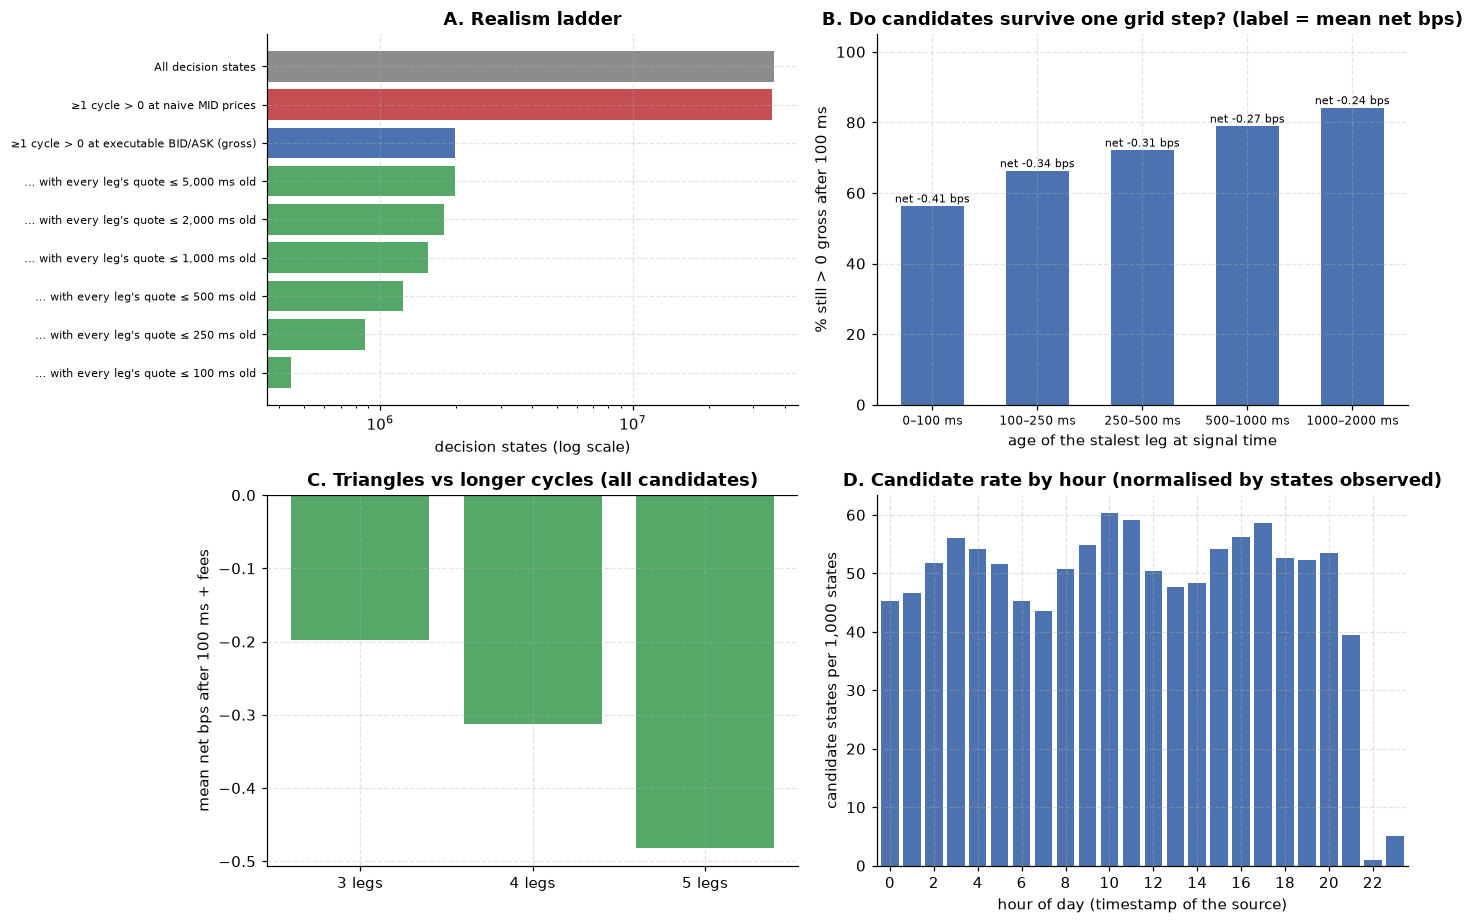

Of 36,292,507 decision states, **98.210 %** contain a cycle with a positive return at naive mid prices, **5.47 %** at executable bid/ask prices, and **1.225 %** when every leg's quote is at most 100 ms old. Panel B shows what happens to the candidates one grid step later.

stalest_leg_age,candidates,mean_gross_bps_at_signal,still_profitable_after_latency_%,mean_net_bps_after_latency_and_fees
str,i64,f64,f64,f64
"""0–100 ms""",893117,0.194166,56.312891,-0.414923
"""100–250 ms""",1321309,0.211118,66.301902,-0.339953
"""250–500 ms""",1572436,0.220682,72.1354,-0.305956
"""500–1000 ms""",1813876,0.224241,78.961186,-0.265677
"""1000–2000 ms""",1681416,0.228153,84.158471,-0.2356


k,candidates,mean_gross_bps_at_signal,still_profitable_after_latency_%,mean_net_bps_after_latency_and_fees
i8,u32,f64,f64,f64
3,2911986,0.215625,77.479768,-0.197675
4,2977360,0.223667,73.04555,-0.313074
5,1392808,0.212452,66.739924,-0.481861


In [11]:
def net_bps(gross_bps, k, fee_leg_bps=FEE_BPS_PER_LEG):
    g = np.asarray(gross_bps, dtype=np.float64)
    return ((1.0 + g / 1e4) * (1.0 - fee_leg_bps * 1e-4) ** np.asarray(k, dtype=np.float64) - 1.0) * 1e4

def net_expr(gcol, fee_leg_bps=FEE_BPS_PER_LEG):
    return ((1.0 + pl.col(gcol).cast(pl.Float64) / 1e4) * pl.lit(1.0 - fee_leg_bps * 1e-4, dtype=pl.Float64).pow(pl.col("k").cast(pl.Float64)) - 1.0) * 1e4

BASE_G = f"g_L{LATENCY_BASE_MS}"
n_states = COUNT["n_states"]

# (a) realism ladder at the STATE level
ladder = [("All decision states", n_states), ("≥1 cycle > 0 at naive MID prices", COUNT["mid_pos_state"]),
          ("≥1 cycle > 0 at executable BID/ASK (gross)", COUNT["ba_pos_state_any"])]
for a in AGE_BUCKETS[::-1]:
    ladder.append((f"… with every leg's quote ≤ {a:,} ms old", COUNT[f"ba_pos_state_age_le_{a}"]))
ladder_df = pl.DataFrame({"stage": [s for s, _ in ladder], "states": [n for _, n in ladder]}).with_columns(
    (pl.col("states") / n_states * 100).alias("pct_of_all_states"))
R["ladder"] = ladder_df.to_dicts(); save_table(ladder_df, "signal_ladder")

# (b) stale quotes: candidates grouped by the age of their stalest leg
edges_age = [0] + AGE_GRID_MS
rows = []
for lo, hi in zip(edges_age[:-1], edges_age[1:]):
    sub = CANDS.filter((pl.col("age_ms") > lo) & (pl.col("age_ms") <= hi)) if lo > 0 else CANDS.filter(pl.col("age_ms") <= hi)
    if sub.height == 0: continue
    g0 = sub["gross_bps"].cast(pl.Float64).to_numpy(); g1 = sub[BASE_G].cast(pl.Float64).to_numpy(); ok = ~np.isnan(g1)
    rows.append({"stalest_leg_age": f"{lo}–{hi} ms", "candidates": sub.height, "mean_gross_bps_at_signal": float(g0.mean()),
                 "still_profitable_after_latency_%": float((g1[ok] > 0).mean() * 100) if ok.any() else float("nan"),
                 "mean_net_bps_after_latency_and_fees": float(net_bps(g1[ok], sub["k"].to_numpy()[ok]).mean()) if ok.any() else float("nan")})
stale_df = pl.DataFrame(rows); R["stale_quotes"] = stale_df.to_dicts(); save_table(stale_df, "stale_quote_anatomy")

# (c) by number of legs and by cycle
def summarise_group(df, by):
    g1 = df[BASE_G].cast(pl.Float64).to_numpy(); netv = net_bps(g1, df["k"].to_numpy())
    return (df.with_columns(pl.Series("net_base", netv), pl.Series("g_base", g1))
              .group_by(by).agg([pl.len().alias("candidates"), pl.col("gross_bps").cast(pl.Float64).mean().alias("mean_gross_bps_at_signal"),
                                 (pl.col("g_base") > 0).mean().mul(100).alias("still_profitable_after_latency_%"),
                                 pl.col("net_base").filter(pl.col("net_base").is_not_nan()).mean().alias("mean_net_bps_after_latency_and_fees")]).sort(by))
by_k = summarise_group(CANDS, "k"); R["by_hops"] = by_k.to_dicts(); save_table(by_k, "candidates_by_legs")
cyc_names = pl.DataFrame({"cyc": [c["id"] for c in CYCLES], "cycle": [c["name"] for c in CYCLES]}, schema={"cyc": pl.Int16, "cycle": pl.Utf8})
by_cycle = summarise_group(CANDS.join(cyc_names, on="cyc"), "cycle").sort("candidates", descending=True)
save_table(by_cycle, "candidates_by_cycle")
R["mid_vs_bidask_cycle_counts_by_k"] = (pl.DataFrame({"k": CYC_K, "mid_pos": COUNT["mid_pos_cycle"], "ba_pos": COUNT["ba_pos_cycle"]})
                                        .group_by("k").agg(pl.col("mid_pos").sum(), pl.col("ba_pos").sum()).sort("k").to_dicts())

fig, axs = plt.subplots(2, 2, figsize=(13, 8.5))
ax = axs[0, 0]; nl = len(ladder)
ax.barh(range(nl)[::-1], [max(n, 0.5) for _, n in ladder], color=["#8c8c8c", "#C44E52", "#4C72B0"] + ["#55A868"] * (nl - 3)); ax.set_xscale("log")
ax.set_yticks(range(nl)[::-1]); ax.set_yticklabels([s for s, _ in ladder], fontsize=7.5); ax.set_xlabel("decision states (log scale)"); ax.set_title("A. Realism ladder")
ax = axs[0, 1]; x = np.arange(stale_df.height)
if stale_df.height:
    ax.bar(x, stale_df["still_profitable_after_latency_%"], 0.6, color="#4C72B0")
    ax.set_xticks(x); ax.set_xticklabels(stale_df["stalest_leg_age"], fontsize=8)
    for xi, (pc, nb) in enumerate(zip(stale_df["still_profitable_after_latency_%"].to_list(), stale_df["mean_net_bps_after_latency_and_fees"].to_list())):
        ax.text(xi, (pc if isnum(pc) else 0) + 1, f"net {fmt(nb, 2, True)} bps", ha="center", fontsize=7.5)
    ax.set_ylim(0, 105)
ax.set_xlabel("age of the stalest leg at signal time"); ax.set_ylabel(f"% still > 0 gross after {LATENCY_BASE_MS} ms")
ax.set_title("B. Do candidates survive one grid step? (label = mean net bps)")
ax = axs[1, 0]; ax.bar([f"{k} legs" for k in by_k["k"]], by_k["mean_net_bps_after_latency_and_fees"], color="#55A868"); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel(f"mean net bps after {LATENCY_BASE_MS} ms + fees"); ax.set_title("C. Triangles vs longer cycles (all candidates)")
ax = axs[1, 1]; seen = COUNT["states_by_hour"] > 0; rate = np.divide(COUNT["fresh_pos_by_hour"], np.maximum(COUNT["states_by_hour"], 1)) * 1e3
ax.bar(np.arange(24)[seen], rate[seen], color="#4C72B0"); ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.6, 23.6)
ax.set_xlabel("hour of day (timestamp of the source)"); ax.set_ylabel("candidate states per 1,000 states")
ax.set_title("D. Candidate rate by hour (normalised by states observed)")
fig.tight_layout(); savefig(fig, "fig_signal_anatomy")

say(f"Of {n_states:,} decision states, **{pct(COUNT['mid_pos_state'] / n_states, 3)}** contain a cycle with a positive return at naive mid prices, "
    f"**{pct(COUNT['ba_pos_state_any'] / n_states)}** at executable bid/ask prices, and **{pct(COUNT[f'ba_pos_state_age_le_{min(AGE_GRID_MS)}'] / n_states, 3)}** "
    f"when every leg's quote is at most {min(AGE_GRID_MS)} ms old. Panel B shows what happens to the candidates one grid step later.")
display(stale_df); display(by_k)

## Stage 8, Strategy and backtest
**Strategy.** At each decision time `T`, among all cycles whose stalest leg is at most `A` ms old, take the one with the highest *net* edge
(executable gross return after fees). Trade it if that edge exceeds `θ` bps. A global cool-down allows at most one trade every `COOLDOWN_MS`
(one arbitrage at a time; the same mispricing is not counted twice through overlapping cycles). The order is **filled `LATENCY_BASE_MS` later at the quotes prevailing then**:
the signal never uses information from after the decision, and the outcome uses only information from the fill time.
**Validation.** `θ` and `A` are tuned **only on the training months**; the test months are untouched until the configuration is frozen.
**Metrics.** Daily PnL from `NOTIONAL_USD` per leg on `CAPITAL_USD`: cumulative return, Sharpe ratio (√252 annualisation over sampled days) and maximum drawdown.
Uncertainty comes from a bootstrap that resamples **whole days**, because trades within a day are not independent.

In [12]:
def cooldown_mask(t_us, cooldown_us):
    keep, last = np.zeros(len(t_us), dtype=bool), None
    for i, t in enumerate(t_us.tolist()):
        if last is None or t - last >= cooldown_us: keep[i] = True; last = t
    return keep

def select_trades(cands, theta, max_age, fee=FEE_BPS_PER_LEG, cooldown_ms=COOLDOWN_MS):
    """Causal trade selection: uses signal-time columns only (gross_bps, age_ms, k, time). Outcomes are attached later by realise()."""
    x = cands.filter(pl.col("age_ms") <= max_age).with_columns(net_expr("gross_bps", fee).alias("net_sig")).filter(pl.col("net_sig") > theta)
    if x.height == 0: return x
    x = x.sort(["time", "net_sig"], descending=[False, True]).unique(subset=["time"], keep="first", maintain_order=True)
    return x.filter(pl.Series(cooldown_mask(x["time"].dt.epoch("us").to_numpy(), cooldown_ms * 1000)))

def realise(trades, latency_ms=LATENCY_BASE_MS, fee=FEE_BPS_PER_LEG, col=None):
    col = col or f"g_L{latency_ms}"
    if trades.height == 0: return trades.with_columns(pl.lit(None, dtype=pl.Float64).alias("real_bps"))
    return trades.with_columns(pl.Series("real_bps", net_bps(trades[col].cast(pl.Float64).to_numpy(), trades["k"].to_numpy(), fee)))

def _valid(tr):
    return tr.filter(pl.col("real_bps").is_not_null() & pl.col("real_bps").is_not_nan()) if tr.height else tr

def daily_pnl(trades_real, period_days):
    """USD PnL per sampled day (0 on days without trades). Trades without an executable quote at fill time are excluded and counted separately."""
    days = sorted(period_days)
    if trades_real.height == 0: return np.zeros(len(days))
    g = _valid(trades_real).group_by("day_idx").agg((pl.col("real_bps") * NOTIONAL_USD / 1e4).sum().alias("pnl"))
    m = dict(zip(g["day_idx"].to_list(), g["pnl"].to_list()))
    return np.array([m.get(d, 0.0) for d in days], dtype=np.float64)

def perf_stats(d_usd):
    d = np.asarray(d_usd, dtype=np.float64); n = len(d)
    if n == 0: return {k: float("nan") for k in ["cum_return", "sharpe", "max_drawdown", "mean_daily_usd", "worst_day_usd", "best_day_usd"]} | {"n_days": 0}
    r = d / CAPITAL_USD; sd = r.std(ddof=1) if n > 1 else float("nan")
    eq = CAPITAL_USD + np.cumsum(d); peak = np.maximum.accumulate(np.concatenate([[CAPITAL_USD], eq]))[1:]
    return {"cum_return": float(r.sum()), "sharpe": float(r.mean() / sd * math.sqrt(252)) if isnum(sd) and sd > 0 else float("nan"),
            "max_drawdown": float(((peak - eq) / peak).max()), "mean_daily_usd": float(d.mean()), "worst_day_usd": float(d.min()),
            "best_day_usd": float(d.max()), "n_days": int(n)}

def trade_stats(tr):
    n_sel = tr.height
    v = _valid(tr)["real_bps"].to_numpy() if n_sel else np.array([])
    base = {"n_trades": int(len(v)), "n_no_fill_quote": int(n_sel - len(v))}
    if len(v) == 0: return base | {"mean_net_bps": float("nan"), "median_net_bps": float("nan"), "hit_rate": float("nan")}
    return base | {"mean_net_bps": float(v.mean()), "median_net_bps": float(np.median(v)), "hit_rate": float((v > 0).mean())}

def day_block_bootstrap(trades_real, period_days, n_boot=N_BOOT, seed=BOOT_SEED):
    """Resamples WHOLE DAYS. Returns a 95 % CI for mean net bps per trade, a one-sided p-value for H0: mean <= 0
    (share of resampled samples with mean <= 0, so it always agrees with the CI), and a 95 % CI for the Sharpe ratio."""
    days = sorted(period_days); nan2 = (float("nan"), float("nan"))
    t = _valid(trades_real) if trades_real.height else trades_real
    if t.height == 0 or len(days) < 2: return {"mean_bps_ci": nan2, "p_mean_le_0": float("nan"), "sharpe_ci": nan2}
    g = t.group_by("day_idx").agg(pl.col("real_bps").sum().alias("s"), pl.len().alias("n"))
    m = {d: (s, n) for d, s, n in zip(g["day_idx"].to_list(), g["s"].to_list(), g["n"].to_list())}
    S = np.array([m.get(d, (0.0, 0))[0] for d in days]); N = np.array([m.get(d, (0.0, 0))[1] for d in days], dtype=np.float64)
    idx = np.random.default_rng(seed).integers(0, len(days), size=(n_boot, len(days)))
    num, den = S[idx].sum(1), N[idx].sum(1)
    means = np.divide(num, den, out=np.full(n_boot, np.nan), where=den > 0)
    ok = means[np.isfinite(means)]
    p = float(np.mean(ok <= 0)) if len(ok) else float("nan")   # share of resampled samples whose mean is not above zero
    pnl = (S * NOTIONAL_USD / 1e4 / CAPITAL_USD)[idx]; sd = pnl.std(axis=1, ddof=1)
    sh = np.divide(pnl.mean(1), sd, out=np.full(n_boot, np.nan), where=sd > 0) * math.sqrt(252)
    sh_ci = (float(np.nanpercentile(sh, 2.5)), float(np.nanpercentile(sh, 97.5))) if np.isfinite(sh).any() else nan2
    return {"mean_bps_ci": (float(np.nanpercentile(means, 2.5)), float(np.nanpercentile(means, 97.5))), "p_mean_le_0": p, "sharpe_ci": sh_ci}

def fmt_p(p):
    if not isnum(p): return "n/a"
    return f"< {1 / N_BOOT:.4f}" if p < 1 / N_BOOT else f"{p:.3f}"

def full_stats(tr_real, period_days):
    return {**trade_stats(tr_real), **perf_stats(daily_pnl(tr_real, period_days)), **day_block_bootstrap(tr_real, period_days),
            "trades_per_day": trade_stats(tr_real)["n_trades"] / max(len(period_days), 1)}

# ---- the split: a rule fixed in advance (first TRAIN_FRACTION of months = training) -----------------
proc = PROCESSED_DAYS.select(["day_idx", "month", "day"]).sort("day_idx")
months_proc = sorted(proc["month"].unique().to_list())
assert len(months_proc) >= 2, "need at least two months of data for a train/test split"
n_train_m = min(max(1, round(TRAIN_FRACTION * len(months_proc))), len(months_proc) - 1)
TRAIN_MONTHS, TEST_MONTHS = months_proc[:n_train_m], months_proc[n_train_m:]
def days_of(months): return proc.filter(pl.col("month").is_in(months))["day_idx"].to_list()
def cands_of(days): return CANDS.filter(pl.col("day_idx").is_in(days))
TRAIN_DAYS, TEST_DAYS = days_of(TRAIN_MONTHS), days_of(TEST_MONTHS)
C_TRAIN, C_TEST = cands_of(TRAIN_DAYS), cands_of(TEST_DAYS)
R["split"] = {"rule": f"first {TRAIN_FRACTION:.0%} of months for training; the rest untouched until the configuration was frozen",
              "train_months": [TRAIN_MONTHS[0], TRAIN_MONTHS[-1]], "test_months": [TEST_MONTHS[0], TEST_MONTHS[-1]],
              "n_train_months": len(TRAIN_MONTHS), "n_test_months": len(TEST_MONTHS), "n_train_days": len(TRAIN_DAYS), "n_test_days": len(TEST_DAYS)}
say(f"**Split:** training {TRAIN_MONTHS[0]} to {TRAIN_MONTHS[-1]} ({len(TRAIN_DAYS)} days) | **test** {TEST_MONTHS[0]} to {TEST_MONTHS[-1]} ({len(TEST_DAYS)} days).")

**Split:** training 2020-04 to 2021-08 (51 days) | **test** 2021-09 to 2022-08 (36 days).

In [13]:
def tune(cands, period_days, counter_key):
    rows = []
    for theta in THETA_GRID_BPS:
        for A in AGE_GRID_MS:
            TRIALS[counter_key] += 1
            tr = realise(select_trades(cands, theta, A))
            ts, ps = trade_stats(tr), perf_stats(daily_pnl(tr, period_days))
            rows.append({"theta_bps": theta, "max_age_ms": A, **ts, "sharpe": ps["sharpe"], "cum_return": ps["cum_return"]})
    grid = pl.DataFrame(rows, schema_overrides={"sharpe": pl.Float64, "cum_return": pl.Float64, "mean_net_bps": pl.Float64,
                                                "median_net_bps": pl.Float64, "hit_rate": pl.Float64})
    grid = grid.with_columns([pl.when(pl.col(c).is_finite()).then(pl.col(c)).otherwise(None).alias(c)
                              for c in ["mean_net_bps", "median_net_bps", "sharpe", "cum_return", "hit_rate"]])
    ok = grid.filter(pl.col("n_trades") >= MIN_TRADES_FOR_SELECTION)
    if ok.height and ok["sharpe"].drop_nulls().len():
        best, why = ok.sort("sharpe", descending=True, nulls_last=True).row(0, named=True), "highest training-period Sharpe among configurations with enough trades"
    elif ok.height:
        best, why = ok.sort("mean_net_bps", descending=True, nulls_last=True).row(0, named=True), "highest training-period mean net bps (Sharpe undefined)"
    else:
        best, why = grid.sort("n_trades", descending=True).row(0, named=True), "no configuration reached the minimum trade count; the most active one was taken"
    return grid, {"theta_bps": best["theta_bps"], "max_age_ms": best["max_age_ms"]}, why

with stage("8. strategy tuning + backtest"):
    TUNE_GRID, SELECTED, WHY = tune(C_TRAIN, TRAIN_DAYS, "initial_tuning")
    TH, AG = SELECTED["theta_bps"], SELECTED["max_age_ms"]
    # configuration frozen above; the test period is used for the first time here
    TR_IS, TR_OOS = realise(select_trades(C_TRAIN, TH, AG)), realise(select_trades(C_TEST, TH, AG))
    KEY = {"in-sample (training)": full_stats(TR_IS, TRAIN_DAYS), "out-of-sample (test)": full_stats(TR_OOS, TEST_DAYS)}

R["selection"] = {"theta_bps": TH, "max_age_ms": AG, "criterion": WHY, "n_configs_in_grid": TUNE_GRID.height, "latency_ms": LATENCY_BASE_MS,
                  "fee_bps_per_leg": FEE_BPS_PER_LEG, "cooldown_ms": COOLDOWN_MS, "notional_usd_per_leg": NOTIONAL_USD, "capital_usd": CAPITAL_USD}
R["key_results"] = KEY; save_table(TUNE_GRID, "tuning_grid_training_period")
display(TUNE_GRID.sort(["theta_bps", "max_age_ms"]))
say(f"**Selected on the training months only** ({WHY}): θ = **{TH} bps**, A = **{AG} ms**; latency {LATENCY_BASE_MS} ms, fee {FEE_BPS_PER_LEG} bps per leg, "
    f"cool-down {COOLDOWN_MS} ms; {TUNE_GRID.height} configurations evaluated.")

def kr(label, f): return [label] + [f(KEY[p]) for p in KEY]
key_rows = [kr("Sampled days", lambda s: f"{s['n_days']}"), kr("Trades", lambda s: f"{s['n_trades']:,}"),
            kr("Trades per day", lambda s: fmt(s["trades_per_day"], 1)),
            kr("Mean net return per trade (bps)", lambda s: fmt(s["mean_net_bps"], 3, True)),
            kr("  95 % CI (day-block bootstrap)", lambda s: f"[{fmt(s['mean_bps_ci'][0], 3, True)}, {fmt(s['mean_bps_ci'][1], 3, True)}]"),
            kr("Hit rate", lambda s: pct(s["hit_rate"], 1)),
            kr(f"Cumulative return (sampled days, ${CAPITAL_USD / 1e6:g}M capital)", lambda s: pct(s["cum_return"], 3, True)),
            kr("Sharpe ratio (annualised, √252)", lambda s: fmt(s["sharpe"], 2, True)),
            kr("  95 % CI (day-block bootstrap)", lambda s: f"[{fmt(s['sharpe_ci'][0], 2, True)}, {fmt(s['sharpe_ci'][1], 2, True)}]"),
            kr("Maximum drawdown", lambda s: pct(s["max_drawdown"], 3)), kr("Worst day (USD)", lambda s: fmt(s["worst_day_usd"], 0, True)),
            kr("One-sided p-value, H0: mean net ≤ 0", lambda s: fmt_p(s["p_mean_le_0"])),
            kr("Trades with no quote at fill time (excluded)", lambda s: f"{s['n_no_fill_quote']:,}")]
KEY_TABLE_MD = md_table(["Metric"] + list(KEY), key_rows)
say("### Key results\n" + KEY_TABLE_MD)
oos = KEY["out-of-sample (test)"]
if oos["n_trades"] < MIN_TRADES_FOR_SELECTION:
    verdict = f"Only {oos['n_trades']} out-of-sample trades: **too few to test H0**."
elif isnum(oos["p_mean_le_0"]) and oos["p_mean_le_0"] < 0.05 and oos["mean_net_bps"] > 0:
    verdict = (f"**H0 is rejected at the 5 % level** for the headline configuration (p {'= ' if oos['p_mean_le_0'] >= 1 / N_BOOT else ''}{fmt_p(oos['p_mean_le_0'])}, mean net {oos['mean_net_bps']:+.3f} bps per trade). "
               f"Stages 9–11 decide whether this survives realistic latency, costs and other periods.")
else:
    verdict = f"**H0 is not rejected** (p = {fmt_p(oos['p_mean_le_0'])}; mean net {fmt(oos['mean_net_bps'], 3, True)} bps per trade out-of-sample)."
R["h0_verdict"] = verdict; say(verdict)

theta_bps,max_age_ms,n_trades,n_no_fill_quote,mean_net_bps,median_net_bps,hit_rate,sharpe,cum_return
f64,i64,i64,i64,f64,f64,f64,f64,f64
0.0,100,2118,0,-0.30305,-0.101812,0.338527,-15.643938,-0.012837
0.0,250,3063,0,-0.267779,-0.077915,0.374796,-15.870599,-0.016404
0.0,500,3611,0,-0.25651,-0.069619,0.397397,-16.052255,-0.018525
0.0,1000,4272,0,-0.23236,-0.056745,0.423455,-15.967843,-0.019853
0.0,2000,5394,0,-0.185654,-0.017121,0.482202,-15.63285,-0.020028
0.1,100,1101,0,-0.388342,-0.127339,0.367847,-14.509788,-0.008551
0.1,250,1526,0,-0.33151,-0.072799,0.416776,-14.262782,-0.010118
0.1,500,1776,0,-0.312762,-0.053441,0.442005,-14.015626,-0.011109
0.1,1000,2041,0,-0.281504,-0.038267,0.464478,-13.075524,-0.011491


**Selected on the training months only** (highest training-period Sharpe among configurations with enough trades): θ = **1.0 bps**, A = **2000 ms**; latency 100 ms, fee 0.1 bps per leg, cool-down 1000 ms; 25 configurations evaluated.

### Key results
| Metric | in-sample (training) | out-of-sample (test) |
|---|---|---|
| Sampled days | 51 | 36 |
| Trades | 129 | 173 |
| Trades per day | 2.5 | 4.8 |
| Mean net return per trade (bps) | -0.585 | -0.634 |
|   95 % CI (day-block bootstrap) | [-1.096, -0.232] | [-2.848, -0.020] |
| Hit rate | 38.0 % | 54.3 % |
| Cumulative return (sampled days, $5M capital) | -0.151 % | -0.219 % |
| Sharpe ratio (annualised, √252) | -6.30 | -5.16 |
|   95 % CI (day-block bootstrap) | [-8.86, -3.67] | [-11.08, -0.26] |
| Maximum drawdown | 0.151 % | 0.220 % |
| Worst day (USD) | -1,527 | -3,680 |
| One-sided p-value, H0: mean net ≤ 0 | 1.000 | 0.979 |
| Trades with no quote at fill time (excluded) | 0 | 0 |

**H0 is not rejected** (p = 0.979; mean net -0.634 bps per trade out-of-sample).

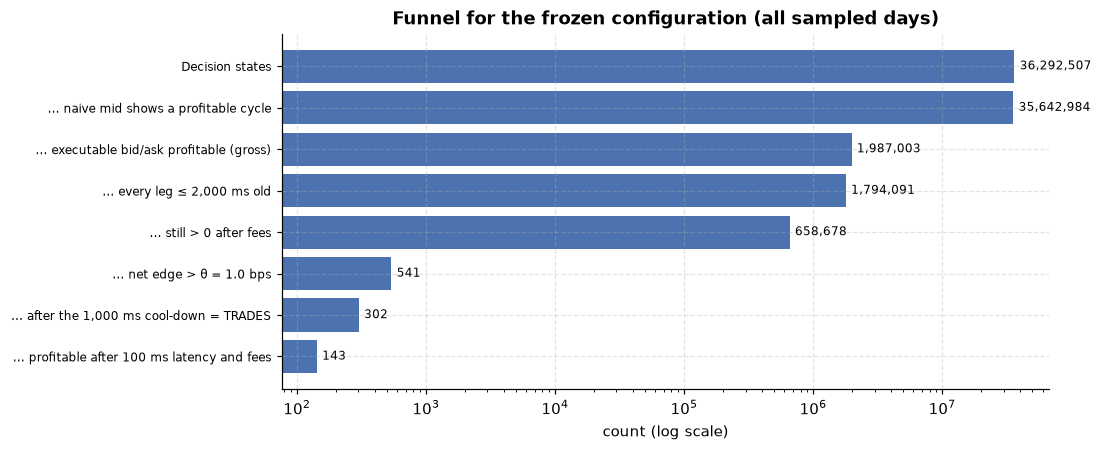

stage,count,pct_of_states
str,i64,f64
"""Decision states""",36292507,100.0
"""… naive mid shows a profitable cycle""",35642984,98.210311
"""… executable bid/ask profitable (gross)""",1987003,5.474968
"""… every leg ≤ 2,000 ms old""",1794091,4.94342
"""… still > 0 after fees""",658678,1.814915
"""… net edge > θ = 1.0 bps""",541,0.001491
"""… after the 1,000 ms cool-down = TRADES""",302,0.000832
"""… profitable after 100 ms latency and fees""",143,0.000394


In [14]:
# ---- funnel for the frozen configuration, all sampled days (every filter uses signal-time information only) ----
x_all = CANDS.filter(pl.col("age_ms") <= AG).with_columns(net_expr("gross_bps").alias("net_sig"))
n_net_pos = x_all.filter(pl.col("net_sig") > 0).select(pl.col("time").n_unique()).item()
n_net_theta = x_all.filter(pl.col("net_sig") > TH).select(pl.col("time").n_unique()).item()
tr_all = realise(select_trades(CANDS, TH, AG)); real_ok = _valid(tr_all)
funnel = [("Decision states", n_states), ("… naive mid shows a profitable cycle", COUNT["mid_pos_state"]),
          ("… executable bid/ask profitable (gross)", COUNT["ba_pos_state_any"]), (f"… every leg ≤ {AG:,} ms old", COUNT[f"ba_pos_state_age_le_{AG}"]),
          ("… still > 0 after fees", n_net_pos), (f"… net edge > θ = {TH} bps", n_net_theta),
          (f"… after the {COOLDOWN_MS:,} ms cool-down = TRADES", tr_all.height),
          (f"… profitable after {LATENCY_BASE_MS} ms latency and fees", int((real_ok["real_bps"] > 0).sum()) if real_ok.height else 0)]
fun_df = pl.DataFrame({"stage": [a for a, _ in funnel], "count": [b for _, b in funnel]}).with_columns((pl.col("count") / n_states * 100).alias("pct_of_states"))
R["funnel"] = fun_df.to_dicts(); save_table(fun_df, "funnel_frozen_config")
fig, ax = plt.subplots(figsize=(9, 4.2)); ax.barh(range(len(funnel))[::-1], [max(b, 0.5) for _, b in funnel], color="#4C72B0"); ax.set_xscale("log")
ax.set_yticks(range(len(funnel))[::-1]); ax.set_yticklabels([a for a, _ in funnel], fontsize=8)
for i, (_, b) in enumerate(funnel): ax.text(max(b, 0.5) * 1.1, len(funnel) - 1 - i, f"{b:,}", va="center", fontsize=8)
ax.set_xlabel("count (log scale)"); ax.set_title("Funnel for the frozen configuration (all sampled days)"); savefig(fig, "fig_funnel")
display(fun_df)

## Stage 9, Latency decay and cost sensitivity (frozen configuration)
Trade *selection* uses signal-time information only, so it is identical in every row of the latency table; only the fill time changes.
0 ms means filling at the very quotes that produced the signal: that is the "paper" result and is not achievable. In the cost table, a higher fee also changes
which signals clear θ, as it would for a trader paying that fee.

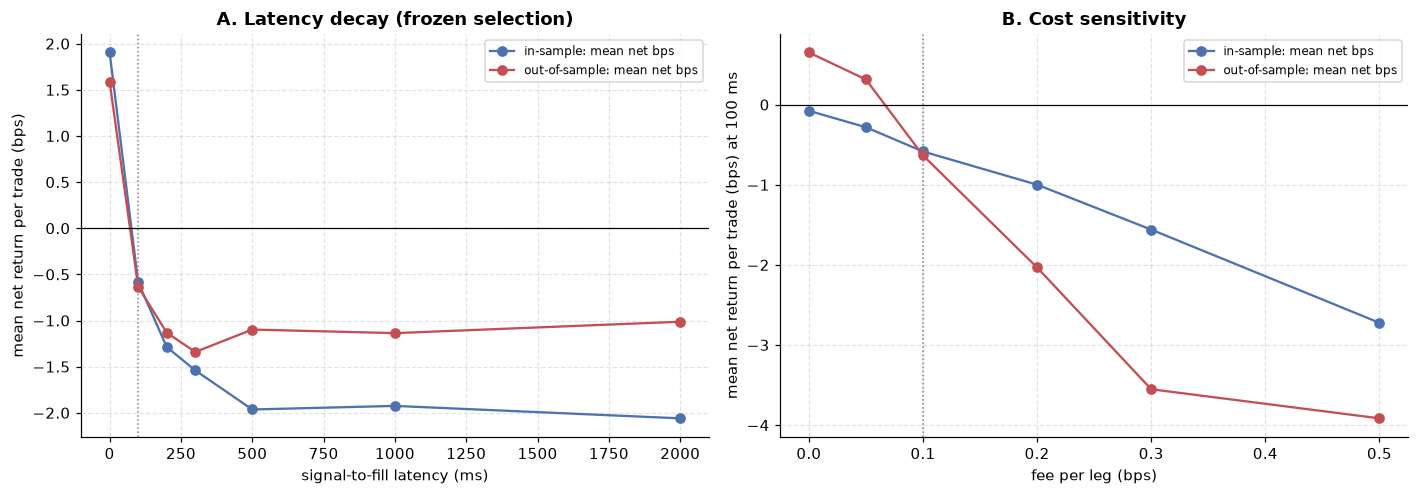

latency_ms,n_trades,mean_net_bps,hit_rate,cum_return,sharpe
i64,i64,f64,f64,f64,f64
0,173,1.588281,1.0,0.005495,7.763445
100,173,-0.633876,0.543353,-0.002193,-5.163692
200,173,-1.130623,0.543353,-0.003912,-5.758517
300,173,-1.341043,0.456647,-0.00464,-6.11429
500,173,-1.098064,0.433526,-0.003799,-7.564925
1000,173,-1.136786,0.364162,-0.003933,-9.581485
2000,173,-1.013351,0.364162,-0.003506,-9.599974


fee_bps_per_leg,n_trades,mean_net_bps,hit_rate,cum_return,sharpe
f64,i64,f64,f64,f64,f64
0.0,3357,0.651312,0.888293,0.043729,3.438144
0.05,666,0.313969,0.795796,0.004182,2.169139
0.1,173,-0.633876,0.543353,-0.002193,-5.163692
0.2,59,-2.032601,0.271186,-0.002398,-8.164274
0.3,35,-3.552528,0.257143,-0.002487,-7.392926
0.5,21,-3.915681,0.190476,-0.001645,-6.296628


**Out-of-sample:** the same trades earn +1.588 bps on paper (0 ms) and -0.634 bps when filled 100 ms later. The mean net return first falls to ≤ 0 at a latency of **100 ms**. At 100 ms it first falls to ≤ 0 at a fee of **0.1 bps per leg**.

In [15]:
def lat_curve(cands, period_days):
    sel = select_trades(cands, TH, AG); rows = []
    for L in LATENCY_GRID_MS:
        tr = realise(sel, L); ts, ps = trade_stats(tr), perf_stats(daily_pnl(tr, period_days))
        rows.append({"latency_ms": L, "n_trades": ts["n_trades"], "mean_net_bps": ts["mean_net_bps"], "hit_rate": ts["hit_rate"],
                     "cum_return": ps["cum_return"], "sharpe": ps["sharpe"]})
    return pl.DataFrame(rows)

def fee_curve(cands, period_days):
    rows = []
    for f in FEE_GRID_BPS:
        tr = realise(select_trades(cands, TH, AG, fee=f), LATENCY_BASE_MS, f); ts, ps = trade_stats(tr), perf_stats(daily_pnl(tr, period_days))
        rows.append({"fee_bps_per_leg": f, "n_trades": ts["n_trades"], "mean_net_bps": ts["mean_net_bps"], "hit_rate": ts["hit_rate"],
                     "cum_return": ps["cum_return"], "sharpe": ps["sharpe"]})
    return pl.DataFrame(rows)

with stage("9. latency + cost sensitivity"):
    LAT = {"in-sample": lat_curve(C_TRAIN, TRAIN_DAYS), "out-of-sample": lat_curve(C_TEST, TEST_DAYS)}
    FEE = {"in-sample": fee_curve(C_TRAIN, TRAIN_DAYS), "out-of-sample": fee_curve(C_TEST, TEST_DAYS)}

def first_nonpositive(df, xcol):
    for r in df.sort(xcol).to_dicts():
        if not isnum(r["mean_net_bps"]) or r["mean_net_bps"] <= 0: return r[xcol]
    return None

lat_oos, fee_oos = LAT["out-of-sample"], FEE["out-of-sample"]
be_lat, be_fee = first_nonpositive(lat_oos, "latency_ms"), first_nonpositive(fee_oos, "fee_bps_per_leg")
R["latency_curve"] = {k: v.to_dicts() for k, v in LAT.items()}; R["fee_curve"] = {k: v.to_dicts() for k, v in FEE.items()}
R["breakeven"] = {"first_latency_ms_with_mean_net_le_0_oos": be_lat, "first_fee_bps_per_leg_with_mean_net_le_0_oos": be_fee}
for k in LAT: save_table(LAT[k], f"latency_curve_{k}"); save_table(FEE[k], f"fee_curve_{k}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for (name, df), c in zip(LAT.items(), ["#4C72B0", "#C44E52"]):
    axs[0].plot(df["latency_ms"], df["mean_net_bps"], "o-", color=c, label=f"{name}: mean net bps")
axs[0].axhline(0, color="k", lw=0.8); axs[0].axvline(LATENCY_BASE_MS, color="grey", ls=":", lw=1)
axs[0].set_xlabel("signal-to-fill latency (ms)"); axs[0].set_ylabel("mean net return per trade (bps)"); axs[0].set_title("A. Latency decay (frozen selection)"); axs[0].legend(fontsize=8)
for (name, df), c in zip(FEE.items(), ["#4C72B0", "#C44E52"]):
    axs[1].plot(df["fee_bps_per_leg"], df["mean_net_bps"], "o-", color=c, label=f"{name}: mean net bps")
axs[1].axhline(0, color="k", lw=0.8); axs[1].axvline(FEE_BPS_PER_LEG, color="grey", ls=":", lw=1)
axs[1].set_xlabel("fee per leg (bps)"); axs[1].set_ylabel(f"mean net return per trade (bps) at {LATENCY_BASE_MS} ms"); axs[1].set_title("B. Cost sensitivity"); axs[1].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "fig_latency_and_costs")
display(lat_oos); display(fee_oos)
r0 = lat_oos.filter(pl.col("latency_ms") == 0).row(0, named=True); rb = lat_oos.filter(pl.col("latency_ms") == LATENCY_BASE_MS).row(0, named=True)
say(f"**Out-of-sample:** the same trades earn {fmt(r0['mean_net_bps'], 3, True)} bps on paper (0 ms) and {fmt(rb['mean_net_bps'], 3, True)} bps when filled "
    f"{LATENCY_BASE_MS} ms later. "
    + (f"The mean net return first falls to ≤ 0 at a latency of **{be_lat:,} ms**. " if be_lat is not None
       else f"The mean net return stays positive at every tested latency (up to {max(LATENCY_GRID_MS):,} ms). ")
    + (f"At {LATENCY_BASE_MS} ms it first falls to ≤ 0 at a fee of **{be_fee} bps per leg**." if be_fee is not None
       else f"At {LATENCY_BASE_MS} ms it stays positive at every tested fee (up to {max(FEE_GRID_BPS)} bps per leg)."))

## Stage 10, Walk-forward validation
A single split can be lucky. Here the parameters are **re-tuned on an expanding window of past months** and applied to the next `WF_TEST_BLOCK_MONTHS` months,
then the window moves forward. Every test block is out-of-sample for the parameters used in it. (These blocks overlap the Stage 8 test period; this is a second,
independent way of validating, not an extra holdout.)

fold,train,test,test_days,theta_bps,max_age_ms,n_trades,mean_net_bps,hit_rate,cum_return,sharpe
i64,str,str,i64,f64,i64,i64,f64,f64,f64,f64
1,"""2020-04..2021-03""","""2021-04..2021-06""",9,1.0,2000,22,-0.548967,0.409091,-0.000242,-5.511529
2,"""2020-04..2021-06""","""2021-07..2021-09""",9,1.0,2000,25,-1.218684,0.36,-0.000609,-11.444481
3,"""2020-04..2021-09""","""2021-10..2021-12""",9,1.0,2000,6,-3.316642,0.5,-0.000398,-5.009733
4,"""2020-04..2021-12""","""2022-01..2022-03""",9,1.0,2000,87,-0.692691,0.528736,-0.001205,-6.804579
5,"""2020-04..2022-03""","""2022-04..2022-06""",9,0.5,2000,2660,0.422131,0.930075,0.022457,5.099072
6,"""2020-04..2022-06""","""2022-07..2022-08""",6,0.5,2000,19,-1.504865,0.210526,-0.000572,-19.547935


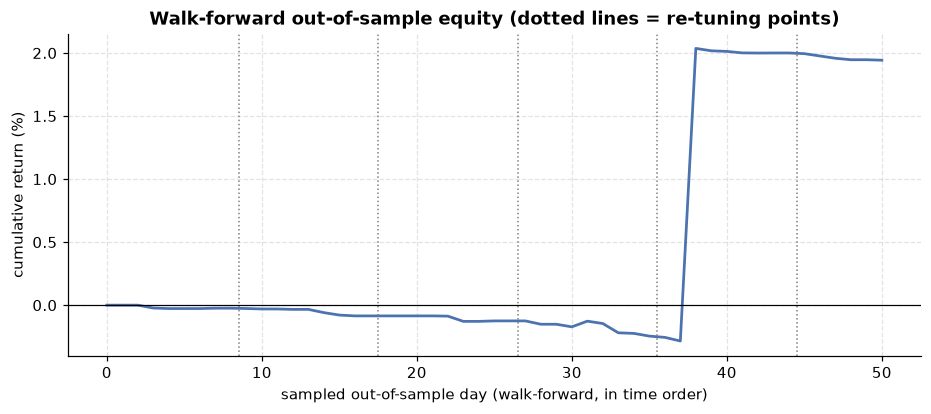

**Walk-forward:** 6 folds; 1 of them have a positive mean net return. Pooled over all walk-forward test days: 2,819 trades, mean net +0.345 bps (95 % CI [-1.995, +0.413], p 0.363), Sharpe +1.85, cumulative return +1.943 %, max drawdown 0.284 %.

In [16]:
with stage("10. walk-forward"):
    n0 = min(max(1, round(WF_MIN_TRAIN_FRACTION * len(months_proc))), len(months_proc) - 1)
    folds, wf_trades, wf_days = [], [], []
    start = n0
    while start < len(months_proc):
        tr_m, te_m = months_proc[:start], months_proc[start:start + WF_TEST_BLOCK_MONTHS]
        d_tr, d_te = days_of(tr_m), days_of(te_m)
        _, sel_cfg, why_f = tune(cands_of(d_tr), d_tr, "walk_forward_retuning")
        tr_te = realise(select_trades(cands_of(d_te), sel_cfg["theta_bps"], sel_cfg["max_age_ms"]))
        ts, ps = trade_stats(tr_te), perf_stats(daily_pnl(tr_te, d_te))
        folds.append({"fold": len(folds) + 1, "train": f"{tr_m[0]}..{tr_m[-1]}", "test": f"{te_m[0]}..{te_m[-1]}", "test_days": len(d_te),
                      "theta_bps": sel_cfg["theta_bps"], "max_age_ms": sel_cfg["max_age_ms"], "n_trades": ts["n_trades"],
                      "mean_net_bps": ts["mean_net_bps"], "hit_rate": ts["hit_rate"], "cum_return": ps["cum_return"], "sharpe": ps["sharpe"]})
        wf_trades.append(tr_te); wf_days += d_te
        start += WF_TEST_BLOCK_MONTHS
    WF_FOLDS = pl.DataFrame(folds)
    WF_TR = pl.concat([t for t in wf_trades if t.height]) if any(t.height for t in wf_trades) else TR_OOS.head(0)
    WF_STATS = full_stats(WF_TR, wf_days)

R["walk_forward"] = {"folds": WF_FOLDS.to_dicts(), "pooled": WF_STATS, "n_folds": WF_FOLDS.height,
                     "folds_with_positive_mean": int(WF_FOLDS.filter(pl.col("mean_net_bps") > 0).height)}
save_table(WF_FOLDS, "walk_forward_folds"); display(WF_FOLDS)
d_wf = daily_pnl(WF_TR, wf_days)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(np.arange(len(d_wf)), np.cumsum(d_wf) / CAPITAL_USD * 100, color="#4C72B0", lw=1.8)
b = 0
for f in folds[:-1]:
    b += f["test_days"]; ax.axvline(b - 0.5, color="grey", ls=":", lw=1)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("sampled out-of-sample day (walk-forward, in time order)"); ax.set_ylabel("cumulative return (%)")
ax.set_title("Walk-forward out-of-sample equity (dotted lines = re-tuning points)"); savefig(fig, "fig_walk_forward")
say(f"**Walk-forward:** {WF_FOLDS.height} folds; {R['walk_forward']['folds_with_positive_mean']} of them have a positive mean net return. "
    f"Pooled over all walk-forward test days: {WF_STATS['n_trades']:,} trades, mean net {fmt(WF_STATS['mean_net_bps'], 3, True)} bps "
    f"(95 % CI [{fmt(WF_STATS['mean_bps_ci'][0], 3, True)}, {fmt(WF_STATS['mean_bps_ci'][1], 3, True)}], p {fmt_p(WF_STATS['p_mean_le_0'])}), "
    f"Sharpe {fmt(WF_STATS['sharpe'], 2, True)}, cumulative return {pct(WF_STATS['cum_return'], 3, True)}, max drawdown {pct(WF_STATS['max_drawdown'], 3)}.")

## Stage 11, Robustness and pitfall checks
(a) **Overfitting:** how well does training-period performance predict test-period performance across the *whole* parameter grid? (diagnostic only, not used to choose anything)
(b) **Cycle length:** triangles only vs up to 4 vs up to 5 legs, with the frozen θ and A.
(c) **Outliers:** does the result depend on a handful of trades or one day?
(d) **Coverage / survivorship:** which pairs are present on which sampled days.

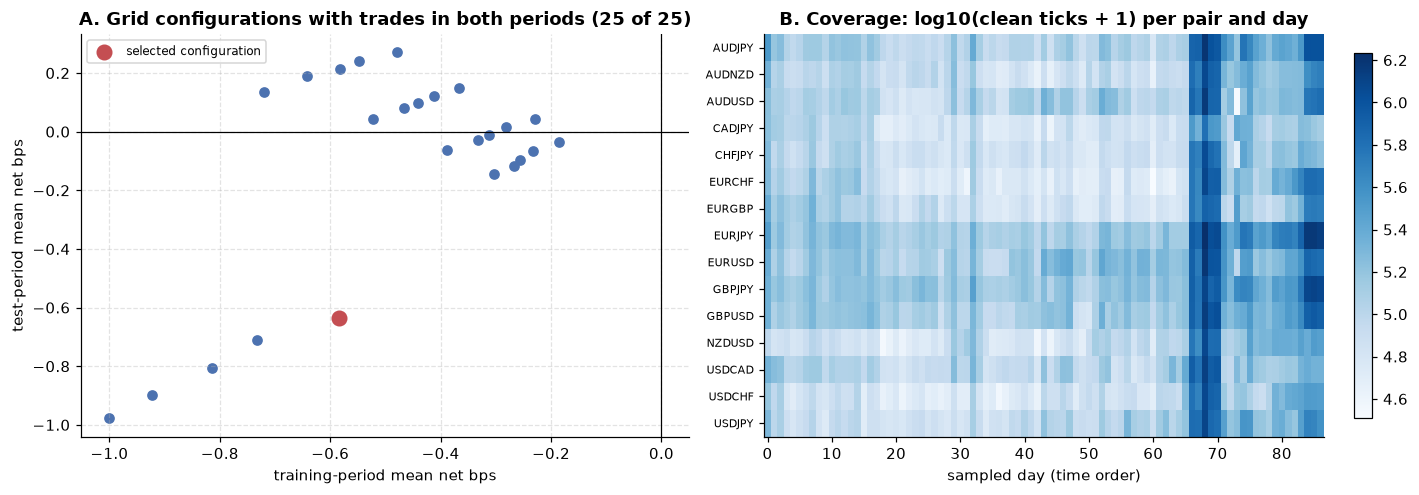

cycles_used,n_trades,mean_net_bps,hit_rate,cum_return,sharpe
str,i64,f64,f64,f64,f64
"""up to 3 legs""",125,-0.703759,0.52,-0.001759,-4.965162
"""up to 4 legs""",170,-0.644017,0.541176,-0.00219,-5.178409
"""up to 5 legs""",173,-0.633876,0.543353,-0.002193,-5.163692


**Overfitting check:** across 25 grid configurations, the Spearman rank correlation between training and test mean net return is **+0.08**; the selected configuration ranks **21 of 25** on the test period. In total 175 configurations were evaluated for selection (25 in the initial tuning, 150 in walk-forward re-tuning).  
**Outliers:** mean -0.634 bps; without the top 1 % of trades -0.671 bps; without the best day -1.093 bps; median +0.115 bps.  
**Coverage:** 0 (pair, day) cells have no clean ticks out of 1305; affected cycles are simply not evaluated on those days (nothing is filled in).

In [17]:
def rank(a):
    return pl.Series(a).rank("average").to_numpy()

with stage("11. robustness checks"):
    # (a) training vs test performance for every grid configuration
    grid_rows = []
    for r in TUNE_GRID.to_dicts():
        tr = realise(select_trades(C_TEST, r["theta_bps"], r["max_age_ms"])); ts, ps = trade_stats(tr), perf_stats(daily_pnl(tr, TEST_DAYS))
        grid_rows.append({"theta_bps": r["theta_bps"], "max_age_ms": r["max_age_ms"], "is_sharpe": r["sharpe"], "oos_sharpe": ps["sharpe"],
                          "is_mean_bps": r["mean_net_bps"], "oos_mean_bps": ts["mean_net_bps"], "oos_trades": ts["n_trades"]})
    GRID_IO = pl.DataFrame(grid_rows, schema_overrides={c: pl.Float64 for c in ["is_sharpe", "oos_sharpe", "is_mean_bps", "oos_mean_bps"]})
    ok = GRID_IO.filter(pl.col("is_mean_bps").is_not_null() & pl.col("oos_mean_bps").is_not_null() & pl.col("is_mean_bps").is_finite() & pl.col("oos_mean_bps").is_finite())
    rho = float(np.corrcoef(rank(ok["is_mean_bps"].to_numpy()), rank(ok["oos_mean_bps"].to_numpy()))[0, 1]) if ok.height >= 3 else float("nan")
    sel_row = GRID_IO.filter((pl.col("theta_bps") == TH) & (pl.col("max_age_ms") == AG)).row(0, named=True)
    oos_rank = int((ok["oos_mean_bps"] > (sel_row["oos_mean_bps"] if isnum(sel_row["oos_mean_bps"]) else -np.inf)).sum()) + 1 if ok.height else None
    # (b) cycle length
    hop_rows = []
    for kmax in range(3, MAX_HOPS + 1):
        tr = realise(select_trades(C_TEST.filter(pl.col("k") <= kmax), TH, AG)); ts, ps = trade_stats(tr), perf_stats(daily_pnl(tr, TEST_DAYS))
        hop_rows.append({"cycles_used": f"up to {kmax} legs", "n_trades": ts["n_trades"], "mean_net_bps": ts["mean_net_bps"], "hit_rate": ts["hit_rate"],
                         "cum_return": ps["cum_return"], "sharpe": ps["sharpe"]})
    HOPS = pl.DataFrame(hop_rows)
    # (c) outliers (out-of-sample, frozen configuration)
    v = _valid(TR_OOS)["real_bps"].to_numpy() if TR_OOS.height else np.array([])
    d_oos = daily_pnl(TR_OOS, TEST_DAYS)
    if len(v) >= 10:
        cut = np.quantile(v, 0.99); v_trim = v[v <= cut]
        best_day = sorted(TEST_DAYS)[int(np.argmax(d_oos))]
        v_nobest = _valid(TR_OOS.filter(pl.col("day_idx") != best_day))["real_bps"].to_numpy()
        OUTL = {"mean_all": float(v.mean()), "median_all": float(np.median(v)), "mean_without_top_1pct_trades": float(v_trim.mean()),
                "mean_without_best_day": float(v_nobest.mean()) if len(v_nobest) else float("nan"),
                "share_of_pnl_from_top_1pct_trades": float(v[v > cut].sum() / v.sum()) if v.sum() != 0 else float("nan"),
                "share_of_pnl_from_best_day": float(d_oos.max() / d_oos.sum()) if d_oos.sum() != 0 else float("nan")}
    else:
        OUTL = {"note": f"only {len(v)} out-of-sample trades; outlier analysis skipped"}
    # (d) coverage: ticks kept per pair per sampled day
    COV = (CLEAN_AUDIT.join(DAY_TABLE.select(["day", "day_idx"]), on="day").select(["day_idx", "pair", "kept"])
           .pivot(on="pair", index="day_idx", values="kept").sort("day_idx"))

R["robustness"] = {"is_vs_oos_grid": GRID_IO.to_dicts(), "spearman_is_vs_oos_mean_bps": rho, "selected_config_oos_rank": oos_rank,
                   "grid_configs_compared": ok.height, "by_max_legs_oos": HOPS.to_dicts(), "outliers_oos": OUTL,
                   "trials": dict(TRIALS)}
save_table(GRID_IO, "grid_training_vs_test"); save_table(HOPS, "oos_by_max_legs")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
axs[0].scatter(GRID_IO["is_mean_bps"], GRID_IO["oos_mean_bps"], color="#4C72B0")
if isnum(sel_row["is_mean_bps"]) and isnum(sel_row["oos_mean_bps"]):
    axs[0].scatter([sel_row["is_mean_bps"]], [sel_row["oos_mean_bps"]], color="#C44E52", s=90, label="selected configuration", zorder=3); axs[0].legend(fontsize=8)
axs[0].axhline(0, color="k", lw=0.8); axs[0].axvline(0, color="k", lw=0.8)
axs[0].set_xlabel("training-period mean net bps"); axs[0].set_ylabel("test-period mean net bps")
axs[0].set_title(f"A. Grid configurations with trades in both periods ({ok.height} of {GRID_IO.height})")
present = [c for c in USED_PAIRS if c in COV.columns]
mat = COV.select(present).fill_null(0).to_numpy().T.astype(float)
im = axs[1].imshow(np.log10(mat + 1), aspect="auto", cmap="Blues")
axs[1].set_yticks(range(len(present))); axs[1].set_yticklabels(present, fontsize=7); axs[1].set_xlabel("sampled day (time order)")
axs[1].set_title("B. Coverage: log10(clean ticks + 1) per pair and day"); fig.colorbar(im, ax=axs[1], fraction=0.03)
axs[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); axs[1].grid(False)
fig.tight_layout(); savefig(fig, "fig_robustness")
display(HOPS)
n_tried = TRIALS["initial_tuning"] + TRIALS["walk_forward_retuning"]
gaps = int((mat == 0).sum())
say(f"**Overfitting check:** across {ok.height} grid configurations, the Spearman rank correlation between training and test mean net return is **{fmt(rho, 2, True)}**; "
    f"the selected configuration ranks **{oos_rank if oos_rank is not None else 'n/a'} of {ok.height}** on the test period. "
    f"In total {n_tried} configurations were evaluated for selection ({TRIALS['initial_tuning']} in the initial tuning, {TRIALS['walk_forward_retuning']} in walk-forward re-tuning).  \n"
    + (f"**Outliers:** mean {fmt(OUTL['mean_all'], 3, True)} bps; without the top 1 % of trades {fmt(OUTL['mean_without_top_1pct_trades'], 3, True)} bps; "
       f"without the best day {fmt(OUTL['mean_without_best_day'], 3, True)} bps; median {fmt(OUTL['median_all'], 3, True)} bps.  \n" if "mean_all" in OUTL else f"**Outliers:** {OUTL['note']}.  \n")
    + f"**Coverage:** {gaps} (pair, day) cells have no clean ticks out of {mat.size}; affected cycles are simply not evaluated on those days "
      f"(nothing is filled in).")

## Stage 11b - Which days drive the profit?
The walk-forward result and some test-period grid settings look positive. This checks whether that profit is spread over many days or comes from one day.
If one day makes almost all the money, the result is not a reliable edge.

In [18]:
def day_pnl_table(tr):
    t = _valid(tr) if tr.height else tr
    if t.height == 0: return pl.DataFrame()
    return (t.group_by("day_idx").agg(pl.len().alias("trades"), (pl.col("real_bps") * NOTIONAL_USD / 1e4).sum().alias("pnl_usd"),
                                      pl.col("real_bps").mean().alias("mean_net_bps"))
             .join(DAY_TABLE, on="day_idx").sort("pnl_usd", descending=True))

with stage("11b. day concentration"):
    # (1) walk-forward trades
    wf_by_day = day_pnl_table(WF_TR)
    BEST_DAY = {}
    if wf_by_day.height:
        b = wf_by_day.row(0, named=True)
        tot = float(wf_by_day["pnl_usd"].sum())
        wf_wo = full_stats(WF_TR.filter(pl.col("day_idx") != b["day_idx"]), [d for d in wf_days if d != b["day_idx"]])
        cyc_day = (_valid(WF_TR).filter(pl.col("day_idx") == b["day_idx"]).join(cyc_names, on="cyc")
                   .group_by("cycle").len().sort("len", descending=True))
        BEST_DAY = {"day": b["day"], "trades": int(b["trades"]), "pnl_usd": float(b["pnl_usd"]), "total_wf_pnl_usd": tot,
                    "share_of_wf_trades": b["trades"] / max(WF_STATS["n_trades"], 1),
                    "top_cycles_that_day": cyc_day.head(5).to_dicts(),
                    "wf_without_that_day": {k: wf_wo[k] for k in ["n_trades", "mean_net_bps", "mean_bps_ci", "p_mean_le_0", "sharpe", "cum_return"]}}
    # (2) every grid setting on the test period: how much depends on its single best day?
    conc_rows = []
    for r in TUNE_GRID.select(["theta_bps", "max_age_ms"]).to_dicts():
        tr = realise(select_trades(C_TEST, r["theta_bps"], r["max_age_ms"]))
        t = day_pnl_table(tr)
        if t.height == 0: continue
        bd = t.row(0, named=True)
        v = _valid(tr).filter(pl.col("day_idx") != bd["day_idx"])["real_bps"].to_numpy()
        conc_rows.append({"theta_bps": r["theta_bps"], "max_age_ms": r["max_age_ms"], "trades": int(t["trades"].sum()),
                          "mean_net_bps": float(_valid(tr)["real_bps"].mean()), "best_day": bd["day"], "best_day_trades": int(bd["trades"]),
                          "mean_net_bps_without_best_day": float(v.mean()) if len(v) else float("nan")})
    CONC = pl.DataFrame(conc_rows)

R["walk_forward"]["best_day"] = BEST_DAY
R["robustness"]["test_period_best_day_by_config"] = CONC.to_dicts()
save_table(wf_by_day, "walk_forward_pnl_by_day"); save_table(CONC, "test_grid_without_best_day")
display(wf_by_day.head(5)); display(CONC)
if BEST_DAY:
    w = BEST_DAY["wf_without_that_day"]
    n_pos = int((CONC["mean_net_bps"] > 0).sum()); n_pos_wo = int((CONC["mean_net_bps_without_best_day"] > 0).sum())
    share = BEST_DAY["pnl_usd"] / BEST_DAY["total_wf_pnl_usd"] if BEST_DAY["total_wf_pnl_usd"] > 0 else float("nan")
    head = "One day dominates." if isnum(share) and share > 0.5 else "Best day check."
    say(f"**{head}** In the walk-forward test, {BEST_DAY['day']} has {BEST_DAY['trades']:,} of {WF_STATS['n_trades']:,} trades "
        f"and makes {BEST_DAY['pnl_usd']:+,.0f} USD, against {BEST_DAY['total_wf_pnl_usd']:+,.0f} USD in total. "
        f"Without that day, the walk-forward mean is {fmt(w['mean_net_bps'], 3, True)} bps per trade over {w['n_trades']:,} trades "
        f"(95 % CI [{fmt(w['mean_bps_ci'][0], 3, True)}, {fmt(w['mean_bps_ci'][1], 3, True)}]).  \n"
        f"Across the {CONC.height} grid settings on the test period, {n_pos} have a positive mean; without each setting's best day, {n_pos_wo} do.")


day_idx,trades,pnl_usd,mean_net_bps,month,day
i32,u32,f64,f64,str,str
74,2640,116045.396437,0.439566,"""2022-04""","""20220428"""
67,52,2257.528669,0.43414,"""2022-02""","""20220209"""
61,2,185.914858,0.929574,"""2021-12""","""20211215"""
43,2,141.457653,0.707288,"""2021-06""","""20210621"""
79,1,24.034515,0.240345,"""2022-06""","""20220621"""


theta_bps,max_age_ms,trades,mean_net_bps,best_day,best_day_trades,mean_net_bps_without_best_day
f64,i64,i64,f64,str,i64,f64
0.0,100,50368,-0.143209,"""20220428""",10864,-0.198285
0.0,250,72728,-0.116642,"""20220428""",14579,-0.16209
0.0,500,84556,-0.095272,"""20220428""",17487,-0.139488
0.0,1000,96451,-0.066976,"""20220428""",21834,-0.11421
0.0,2000,109402,-0.035523,"""20220428""",27843,-0.089356
0.1,100,33559,-0.061137,"""20220428""",7114,-0.110768
0.1,250,51434,-0.027855,"""20220209""",34829,-0.188189
0.1,500,61027,-0.009691,"""20220209""",41540,-0.157163
0.1,1000,70577,0.016424,"""20220209""",47474,-0.106505


**One day dominates.** In the walk-forward test, 20220428 has 2,640 of 2,819 trades and makes +116,045 USD, against +97,157 USD in total. Without that day, the walk-forward mean is -1.055 bps per trade over 179 trades (95 % CI [-2.244, -0.337]).  
Across the 25 grid settings on the test period, 12 have a positive mean; without each setting's best day, 6 do.

## Stage 12, Risk touchpoint
Beyond Sharpe and drawdown: how large the positions are, how concentrated the trading is, how bad the tail of single trades is, and what plausible bad scenarios
(slower execution, a liquidity crunch that widens spreads, higher fees) do to the out-of-sample result. All figures use the frozen configuration on the test period.

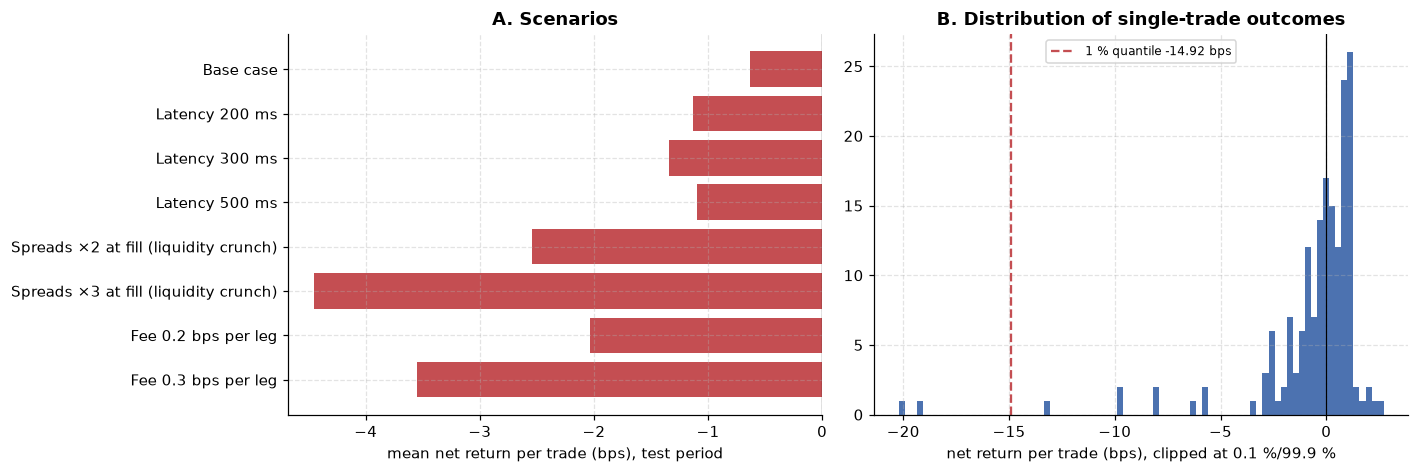

scenario,n_trades,mean_net_bps,hit_rate,cum_return,max_drawdown,worst_day_usd
str,i64,f64,f64,f64,f64,f64
"""Base case""",173,-0.633876,0.543353,-0.002193,0.002199,-3679.582881
"""Latency 200 ms""",173,-1.130623,0.543353,-0.003912,0.003912,-7617.935716
"""Latency 300 ms""",173,-1.341043,0.456647,-0.00464,0.00464,-8803.090335
"""Latency 500 ms""",173,-1.098064,0.433526,-0.003799,0.003799,-4036.193987
"""Spreads ×2 at fill (liquidity crunch)""",173,-2.544913,0.242775,-0.008805,0.008805,-7199.421102
"""Spreads ×3 at fill (liquidity crunch)""",173,-4.455135,0.138728,-0.015415,0.015415,-14795.198803
"""Fee 0.2 bps per leg""",59,-2.032601,0.271186,-0.002398,0.002398,-2916.927562
"""Fee 0.3 bps per leg""",35,-3.552528,0.257143,-0.002487,0.002487,-3565.405737


cycle,trades,pnl_usd,share_of_trades
str,u32,f64,f64
"""EUR>JPY>USD>EUR""",34,140.965405,0.196532
"""EUR>JPY>GBP>EUR""",30,1085.395031,0.17341
"""CHF>JPY>GBP>EUR>CHF""",24,881.646826,0.138728
"""CAD>USD>EUR>JPY>CAD""",23,145.284863,0.132948
"""EUR>USD>JPY>EUR""",6,-963.71134,0.034682
"""AUD>USD>NZD>AUD""",6,-364.191094,0.034682
"""AUD>NZD>USD>AUD""",6,-1668.902497,0.034682
"""CHF>USD>EUR>CHF""",5,-1207.333449,0.028902
"""CHF>EUR>USD>CHF""",4,-413.450026,0.023121


**Sizing:** 1,000,000 USD per leg on 5,000,000 USD of capital; an average trade has 3.40 legs, i.e. 0.68× capital of gross notional, and daily turnover is 3.3× capital.  
**Concentration:** 32 cycles traded; the top cycle (EUR>JPY>USD>EUR) accounts for 19.7 % of trades, the top five for 67.6 % (effective number of cycles 8.9).  
**Tail:** worst trade -20.42 bps, 1 % quantile -14.92 bps, expected shortfall (1 %) -19.84 bps, worst day -3,680 USD.

In [19]:
with stage("12. risk"):
    trv = _valid(TR_OOS)
    v = trv["real_bps"].to_numpy() if trv.height else np.array([])
    mean_k = float(trv["k"].cast(pl.Float64).mean()) if trv.height else float("nan")
    tpd = KEY["out-of-sample (test)"]["trades_per_day"]
    sizing = {"notional_per_leg_usd": NOTIONAL_USD, "capital_usd": CAPITAL_USD, "mean_legs_per_trade": mean_k,
              "gross_notional_per_trade_over_capital": mean_k * NOTIONAL_USD / CAPITAL_USD if isnum(mean_k) else float("nan"),
              "daily_turnover_over_capital": tpd * mean_k * NOTIONAL_USD / CAPITAL_USD if isnum(mean_k) else float("nan")}
    if trv.height:
        by_c = (trv.join(cyc_names, on="cyc").group_by("cycle").agg(pl.len().alias("trades"), (pl.col("real_bps") * NOTIONAL_USD / 1e4).sum().alias("pnl_usd"))
                .with_columns((pl.col("trades") / pl.col("trades").sum()).alias("share_of_trades")).sort("trades", descending=True))
        hhi = float((by_c["share_of_trades"] ** 2).sum())
        ccy_share = {c: float(np.mean([c in CYCLES[int(i)]["ccy"] for i in trv["cyc"].to_list()])) for c in CCY}
        q01 = float(np.quantile(v, 0.01)); es01 = float(v[v <= q01].mean())
        tail = {"worst_trade_bps": float(v.min()), "p1_trade_bps": q01, "expected_shortfall_1pct_bps": es01,
                "worst_day_usd": KEY["out-of-sample (test)"]["worst_day_usd"]}
    else:
        by_c, hhi, ccy_share, tail = pl.DataFrame({"cycle": [], "trades": [], "pnl_usd": [], "share_of_trades": []}), float("nan"), {}, {}
    conc = {"n_cycles_traded": by_c.height, "top_cycle": by_c["cycle"][0] if by_c.height else None,
            "top_cycle_share_of_trades": float(by_c["share_of_trades"][0]) if by_c.height else float("nan"),
            "top5_share_of_trades": float(by_c["share_of_trades"].head(5).sum()) if by_c.height else float("nan"),
            "herfindahl": hhi, "effective_number_of_cycles": 1 / hhi if isnum(hhi) and hhi > 0 else float("nan"),
            "share_of_trades_involving_currency": ccy_share}
    sel_oos = select_trades(C_TEST, TH, AG)
    scen = [("Base case", realise(sel_oos))]
    for L in [x for x in LATENCY_GRID_MS if x > LATENCY_BASE_MS][:3]: scen.append((f"Latency {L:,} ms", realise(sel_oos, L)))
    for m, col in zip(STRESS_SPREAD_MULTS, STRESS_COLS): scen.append((f"Spreads ×{m:g} at fill (liquidity crunch)", realise(sel_oos, col=col)))
    for f in [x for x in FEE_GRID_BPS if x > FEE_BPS_PER_LEG][:2]: scen.append((f"Fee {f} bps per leg", realise(select_trades(C_TEST, TH, AG, fee=f), fee=f)))
    SCEN = pl.DataFrame([{"scenario": n, **{k: s[k] for k in ["n_trades", "mean_net_bps", "hit_rate"]},
                          **{k: p[k] for k in ["cum_return", "max_drawdown", "worst_day_usd"]}}
                         for n, t in scen for s, p in [(trade_stats(t), perf_stats(daily_pnl(t, TEST_DAYS)))]])

R["risk"] = {"sizing": sizing, "concentration": conc, "tail": tail, "scenarios": SCEN.to_dicts()}
save_table(SCEN, "risk_scenarios"); save_table(by_c, "oos_trades_by_cycle")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].barh(SCEN["scenario"].to_list()[::-1], SCEN["mean_net_bps"].fill_null(0).to_list()[::-1],
            color=["#55A868" if (x or 0) > 0 else "#C44E52" for x in SCEN["mean_net_bps"].to_list()[::-1]])
axs[0].axvline(0, color="k", lw=0.8); axs[0].set_xlabel("mean net return per trade (bps), test period"); axs[0].set_title("A. Scenarios")
if len(v):
    axs[1].hist(np.clip(v, np.quantile(v, 0.001), np.quantile(v, 0.999)), bins=80, color="#4C72B0")
    axs[1].axvline(0, color="k", lw=0.8); axs[1].axvline(tail["p1_trade_bps"], color="#C44E52", ls="--", label=f"1 % quantile {tail['p1_trade_bps']:+.2f} bps"); axs[1].legend(fontsize=8)
axs[1].set_xlabel("net return per trade (bps), clipped at 0.1 %/99.9 %"); axs[1].set_title("B. Distribution of single-trade outcomes")
fig.tight_layout(); savefig(fig, "fig_risk")
display(SCEN); display(by_c.head(10))
say(f"**Sizing:** {NOTIONAL_USD:,} USD per leg on {CAPITAL_USD:,} USD of capital; an average trade has {fmt(mean_k, 2)} legs, i.e. "
    f"{fmt(sizing['gross_notional_per_trade_over_capital'], 2)}× capital of gross notional, and daily turnover is {fmt(sizing['daily_turnover_over_capital'], 1)}× capital.  \n"
    f"**Concentration:** {conc['n_cycles_traded']} cycles traded; the top cycle ({conc['top_cycle']}) accounts for {pct(conc['top_cycle_share_of_trades'], 1)} of trades, "
    f"the top five for {pct(conc['top5_share_of_trades'], 1)} (effective number of cycles {fmt(conc['effective_number_of_cycles'], 1)}).  \n"
    + (f"**Tail:** worst trade {fmt(tail['worst_trade_bps'], 2, True)} bps, 1 % quantile {fmt(tail['p1_trade_bps'], 2, True)} bps, "
       f"expected shortfall (1 %) {fmt(tail['expected_shortfall_1pct_bps'], 2, True)} bps, worst day {fmt(tail['worst_day_usd'], 0, True)} USD." if tail else "**Tail:** no out-of-sample trades."))

## Stage 13, Efficiency touchpoint
Measured wall-clock time of every pipeline step, plus a benchmark of three ways to evaluate one market state on real snapshot states:
the vectorised scanner (all enumerated cycles at once), a pure-python loop over the same cycles, and Bellman–Ford.

In [20]:
def bench(fn, reps=3):
    best = math.inf
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

with stage("13. efficiency benchmark"):
    Sb = S[: min(300, len(S))]
    big = pl.DataFrame(cols, schema={c: pl.Float64 for c in cols}).head(len(Sb))
    reps_rows = max(1, 20_000 // max(big.height, 1)); big = pl.concat([big] * reps_rows)          # ~20k rows for a stable timing
    t_vec = {}
    for kmax in range(3, MAX_HOPS + 1):
        ex = [e for e, c in zip(BA_EXPRS, CYCLES) if c["k"] <= kmax]
        t_vec[kmax] = bench(lambda: big.select(ex).to_numpy()) / big.height
    t_py = bench(lambda: [[python_cycle_bps(c, s["quotes"]) for c in CYCLES] for s in Sb]) / len(Sb)
    t_bf = bench(lambda: [eng_real.find_negative_cycle(eng_real.edges_from_quotes(s["quotes"])) for s in Sb]) / len(Sb)

V_, E_ = len(CCY), 2 * len(USED_PAIRS)
BENCH = pl.DataFrame({"method": [f"vectorised scanner, cycles up to {k} legs ({int((CYC_K <= k).sum())} cycles)" for k in t_vec]
                      + [f"pure-python loop over all {N_CYC} cycles", f"Bellman-Ford (V={V_}, E={E_})"],
                      "microseconds_per_state": [t * 1e6 for t in t_vec.values()] + [t_py * 1e6, t_bf * 1e6]})
TIMES = pl.DataFrame({"step": list(STAGE_TIMES), "seconds": list(STAGE_TIMES.values())}).sort("seconds", descending=True)
TIMES = TIMES.with_columns((pl.col("seconds") / pl.col("seconds").sum() * 100).alias("share_%"))
top = TIMES.row(0, named=True)
R["efficiency"] = {"stage_seconds": dict(STAGE_TIMES), "most_expensive_step": top["step"], "most_expensive_seconds": top["seconds"],
                   "benchmark_us_per_state": dict(zip(BENCH["method"].to_list(), BENCH["microseconds_per_state"].to_list())),
                   "n_states": n_states, "n_cycles": N_CYC, "V": V_, "E": E_,
                   "mean_legs_per_cycle": float(CYC_K.mean())}
save_table(TIMES, "stage_timings"); save_table(BENCH, "per_state_benchmark")
display(TIMES); display(BENCH)
say(f"**Most expensive step:** *{top['step']}*, {top['seconds']:,.1f} s ({top['share_%']:.0f} % of measured time). "
    f"The scan costs O(S · C · k̄): S = {n_states:,} states × C = {N_CYC} cycles × k̄ = {CYC_K.mean():.2f} legs per cycle, plus one as-of join per latency "
    f"(O(n log n) in the number of candidates). Per state, the vectorised scanner took {t_vec[MAX_HOPS] * 1e6:,.1f} µs for all {N_CYC} cycles, "
    f"versus {t_py * 1e6:,.1f} µs for the same cycles in a python loop and {t_bf * 1e6:,.1f} µs for Bellman–Ford, whose O(V·E) = O({V_}·{E_}) cost does not depend on cycle length. "
    f"Enumeration stays cheap here because the graph is small ({N_CYC} cycles of up to {MAX_HOPS} legs); the number of cycles grows roughly exponentially with the "
    f"maximum length, which is when Bellman–Ford becomes the better tool.")

step,seconds,share_%
str,f64,f64
"""5c. cycle evaluation + latency look-ups""",70.134395,60.75437
"""5a. load + clean ticks""",27.998339,24.253741
"""5b. causal alignment (as-of joins)""",9.702662,8.404993
"""10. walk-forward""",2.573851,2.229615
"""11. robustness checks""",1.353198,1.172217
"""11b. day concentration""",1.158541,1.003594
"""4. alignment (demo day) + look-ahead tests""",0.733308,0.635233
"""2. snapshot: build or load + verify checksums""",0.411152,0.356163
"""6. Bellman-Ford tests + cross-check""",0.356751,0.309038


method,microseconds_per_state
str,f64
"""vectorised scanner, cycles up to 3 legs (20 cycles)""",0.205084
"""vectorised scanner, cycles up to 4 legs (54 cycles)""",0.228136
"""vectorised scanner, cycles up to 5 legs (90 cycles)""",0.390175
"""pure-python loop over all 90 cycles""",18.36264
"""Bellman-Ford (V=8, E=30)""",8.356527


**Most expensive step:** *5c. cycle evaluation + latency look-ups*, 70.1 s (61 % of measured time). The scan costs O(S · C · k̄): S = 36,292,507 states × C = 90 cycles × k̄ = 4.18 legs per cycle, plus one as-of join per latency (O(n log n) in the number of candidates). Per state, the vectorised scanner took 0.4 µs for all 90 cycles, versus 18.4 µs for the same cycles in a python loop and 8.4 µs for Bellman–Ford, whose O(V·E) = O(8·30) cost does not depend on cycle length. Enumeration stays cheap here because the graph is small (90 cycles of up to 5 legs); the number of cycles grows roughly exponentially with the maximum length, which is when Bellman–Ford becomes the better tool.

## Stage 14, Optional: order-book depth check on Dukascopy data
The Kaggle archive has top-of-book prices but **no quoted sizes**, so the main backtest cannot charge for trading more than the size shown at the best price.
Dukascopy tick files do include top-of-book size. If such files are present (`{PAIR}_{YYYYMMDD}_{HH}.parquet` in `data/` or `data/dukascopy/`, with columns
`time, bid, ask, bid_vol, ask_vol`), this stage re-evaluates the EUR–GBP–USD triangles with a **size-dependent slippage penalty** and **pruning of legs whose quoted
size is too small**. With `FETCH_DUKASCOPY = True` it downloads one hour first (public data, no credentials). If no files are found, the stage is skipped and says so.

In [21]:
DUKA_DIR = DATA_DIR / "dukascopy"
DUKA_RE = re.compile(r"^([A-Z]{6})_(\d{8})_(\d{2})\.parquet$")

def fetch_dukascopy_hour(pair, dt, max_retries=5):
    """Download and decode one hour of Dukascopy .bi5 ticks (LZMA-compressed big-endian records: ms, ask, bid, ask_vol, bid_vol)."""
    import lzma, struct, requests
    url = f"https://datafeed.dukascopy.com/datafeed/{pair}/{dt.year}/{dt.month - 1:02d}/{dt.day:02d}/{dt.hour:02d}h_ticks.bi5"   # month is 0-based in the URL
    for attempt in range(1, max_retries + 1):
        try:
            r = requests.get(url, timeout=45, headers={"User-Agent": "Mozilla/5.0"})
            if r.status_code == 200 and r.content:
                recs = list(struct.iter_unpack(">IIIff", lzma.decompress(r.content)))
                scale = 1e3 if pair.endswith("JPY") else 1e5
                return pl.DataFrame({"time": [dt + timedelta(milliseconds=ms) for ms, *_ in recs], "bid": [b / scale for _, _a, b, *_ in recs],
                                     "ask": [a / scale for _, a, *_ in recs], "bid_vol": [bv for *_, bv in recs], "ask_vol": [av for *_, av, _bv in recs]})
            if r.status_code == 404: return pl.DataFrame()
        except Exception as e:
            print(f"  {pair} attempt {attempt}: {e}")
        time.sleep(2 ** attempt)
    return pl.DataFrame()

def find_duka_hours():
    found = {}
    for d in (DUKA_DIR, DATA_DIR):
        if d.exists():
            for p in sorted(d.glob("*.parquet")):
                m = DUKA_RE.match(p.name)
                if m and m.group(1) in DUKA_PAIRS: found.setdefault(f"{m.group(2)}_{m.group(3)}", {}).setdefault(m.group(1), p)
    return {k: v for k, v in sorted(found.items()) if set(v) == set(DUKA_PAIRS)}

def depth_cycle_exprs(cycle, size_m, fee):
    """Gross top-of-book bps, net bps after fees and depth slippage (null if any leg is pruned)."""
    prod_top, prod_depth, tradeable = pl.lit(1.0), pl.lit(1.0), pl.lit(True)
    for p, d in cycle["legs"]:
        rate = pl.col(f"{p}_bid") if d == "direct" else 1.0 / pl.col(f"{p}_ask")
        vol = pl.col(f"{p}_bid_vol") if d == "direct" else pl.col(f"{p}_ask_vol")   # selling base hits bids; buying base lifts offers
        slip = DEPTH_SLIP_BPS_PER_EXCESS * 1e-4 * pl.max_horizontal(pl.lit(0.0), size_m / vol - 1.0)
        prod_top = prod_top * rate
        prod_depth = prod_depth * rate * (1 - fee * 1e-4) * (1 - slip)
        tradeable = tradeable & (vol >= DEPTH_PRUNE_FRACTION * size_m)
    return ((prod_top - 1) * 1e4), pl.when(tradeable).then((prod_depth - 1) * 1e4).otherwise(None)

with stage("14. Dukascopy depth check (optional)"):
    if FETCH_DUKASCOPY:
        DUKA_DIR.mkdir(parents=True, exist_ok=True); dt0 = datetime.strptime(f"{DUKA_FETCH_DATE} {DUKA_FETCH_HOUR:02d}", "%Y-%m-%d %H")
        for pair in DUKA_PAIRS:
            out = DUKA_DIR / f"{pair}_{dt0:%Y%m%d_%H}.parquet"
            if not out.exists():
                df = fetch_dukascopy_hour(pair, dt0)
                if df.height: df.write_parquet(out); print(f"downloaded {pair}: {df.height:,} ticks")
                else: print(f"could not download {pair} for {dt0}")
    hours = find_duka_hours()
    duka_rows = []
    size_m = NOTIONAL_USD / 1e6
    dcyc = [{"name": ">".join(path), "legs": legs} for path, legs in enumerate_cycles(build_adjacency(DUKA_PAIRS), 3)]
    for stamp, files in hours.items():
        ticks = {}
        for pair, path in files.items():
            raw = pl.read_parquet(path)
            if not {"time", "bid", "ask", "bid_vol", "ask_vol"} <= set(raw.columns): continue
            raw = raw.select([pl.col("time").cast(pl.Datetime("us")), *[pl.col(c).cast(pl.Float64) for c in ["bid", "ask", "bid_vol", "ask_vol"]]])
            ticks[pair] = clean_ticks(raw)[0]
        if len(ticks) < 3: continue
        st = build_day_state(ticks, value_cols=("bid", "ask", "bid_vol", "ask_vol")).drop_nulls()
        for c in dcyc:
            top_e, dep_e = depth_cycle_exprs(c, size_m, FEE_BPS_PER_LEG)
            age_e = pl.max_horizontal([(pl.col("time") - pl.col(f"{p}_ts")).dt.total_milliseconds() for p, _ in c["legs"]])
            sig = st.select(pl.col("time"), top_e.alias("gross"), dep_e.alias("net_depth"), age_e.alias("age"))
            fut = (sig.select((pl.col("time") + pl.duration(milliseconds=LATENCY_BASE_MS)).alias("time"))
                   .join_asof(st, on="time", strategy="backward").select(dep_e.alias("net_depth_fill")))
            sig = sig.with_columns(fut["net_depth_fill"])
            trade = sig.filter((pl.col("net_depth") > TH) & (pl.col("age") <= AG))
            fills = trade["net_depth_fill"].drop_nulls().drop_nans()
            duka_rows.append({"hour": stamp, "cycle": c["name"], "states": st.height,
                              "gross_top_of_book_>0": int((sig["gross"] > 0).sum()),
                              "net_after_fees_and_depth_>0": int((sig["net_depth"] > 0).sum()),
                              "legs_pruned_(state_count)": int(sig["net_depth"].null_count()),
                              f"signals_(net>θ, age≤{AG}ms)": trade.height,
                              f"mean_net_bps_after_{LATENCY_BASE_MS}ms": float(fills.mean()) if fills.len() else float("nan"),
                              "hit_rate": float((fills > 0).mean()) if fills.len() else float("nan")})
DUKA = pl.DataFrame(duka_rows) if duka_rows else None
R["dukascopy_depth_check"] = {"ran": DUKA is not None, "hours": list(hours), "rows": DUKA.to_dicts() if DUKA is not None else [],
                              "assumptions": {"order_size_millions": size_m, "slip_bps_per_excess_multiple": DEPTH_SLIP_BPS_PER_EXCESS,
                                              "prune_fraction": DEPTH_PRUNE_FRACTION}}
if DUKA is not None:
    save_table(DUKA, "dukascopy_depth_check"); display(DUKA)
    say(f"Depth check ran on {len(hours)} Dukascopy hour(s) for {', '.join(DUKA_PAIRS)} with an order of {size_m:g} million per leg. "
        f"Across them, {int(DUKA['gross_top_of_book_>0'].sum()):,} (state, cycle) values are profitable at top-of-book prices and "
        f"{int(DUKA['net_after_fees_and_depth_>0'].sum()):,} remain profitable after fees and the depth penalty.")
else:
    say("**Depth check skipped:** no complete set of Dukascopy files was found in `data/` or `data/dukascopy/`. "
        "Main results above do not depend on this stage.")

hour,cycle,states,gross_top_of_book_>0,net_after_fees_and_depth_>0,legs_pruned_(state_count),"signals_(net>θ, age≤2000ms)",mean_net_bps_after_100ms,hit_rate
str,str,i64,i64,i64,i64,i64,f64,f64
"""20261014_13""","""EUR>USD>GBP>EUR""",19931,6,0,0,0,NaN,NaN
"""20261014_13""","""EUR>GBP>USD>EUR""",19931,3,0,0,0,NaN,NaN


Depth check ran on 1 Dukascopy hour(s) for EURUSD, GBPUSD, EURGBP with an order of 1 million per leg. Across them, 9 (state, cycle) values are profitable at top-of-book prices and 0 remain profitable after fees and the depth penalty.

## Stage 15, Export
Everything quoted in the report comes from `data/derived/results.json` (all numbers), `data/derived/key_results.md` (the key-results table), and the CSV tables and figures in `data/derived/`.

In [22]:
R["trials"] = dict(TRIALS)
R["stage_seconds"] = dict(STAGE_TIMES)
R["environment"] = {"python": platform.python_version(), "polars": pl.__version__, "numpy": np.__version__, "platform": platform.platform(),
                    "run_finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}
R["assumptions"] = {k: globals()[k] for k in ["UNIVERSE", "MAX_HOPS", "SNAPSHOT_DAYS_PER_MONTH", "SNAPSHOT_SEED", "MIN_DAY_TICK_SHARE", "MAX_SPREAD_BPS",
                                              "MAX_JUMP_BPS", "JUMP_WINDOW", "GRID_MS", "MAX_STATE_AGE_MS", "FEE_BPS_PER_LEG", "FEE_GRID_BPS",
                                              "LATENCY_BASE_MS", "LATENCY_GRID_MS", "COOLDOWN_MS", "NOTIONAL_USD", "CAPITAL_USD", "STRESS_SPREAD_MULTS",
                                              "THETA_GRID_BPS", "AGE_GRID_MS", "MIN_TRADES_FOR_SELECTION", "TRAIN_FRACTION", "WF_MIN_TRAIN_FRACTION",
                                              "WF_TEST_BLOCK_MONTHS", "N_BOOT", "BOOT_SEED"]}
R["figures"] = sorted(p.name for p in FIG_DIR.glob("*.png")); R["tables"] = sorted(p.name for p in TAB_DIR.glob("*.csv"))
(DERIVED_DIR / "results.json").write_text(json.dumps(jsonable(R), indent=1))
summary_md = (f"# Key results (generated {R['environment']['run_finished_utc']} UTC)\n\n"
              f"Configuration chosen on {R['split']['train_months'][0]}..{R['split']['train_months'][1]}: θ = {TH} bps, A = {AG} ms, latency {LATENCY_BASE_MS} ms, "
              f"fee {FEE_BPS_PER_LEG} bps per leg. Test period {R['split']['test_months'][0]}..{R['split']['test_months'][1]}.\n\n"
              + KEY_TABLE_MD + f"\n\n{verdict}\n\n## Walk-forward (pooled out-of-sample)\n\n"
              + md_table(["trades", "mean net bps", "95 % CI", "p (H0: ≤ 0)", "Sharpe", "cumulative return", "max drawdown"],
                         [[f"{WF_STATS['n_trades']:,}", fmt(WF_STATS["mean_net_bps"], 3, True),
                           f"[{fmt(WF_STATS['mean_bps_ci'][0], 3, True)}, {fmt(WF_STATS['mean_bps_ci'][1], 3, True)}]", fmt_p(WF_STATS["p_mean_le_0"]),
                           fmt(WF_STATS["sharpe"], 2, True), pct(WF_STATS["cum_return"], 3, True), pct(WF_STATS["max_drawdown"], 3)]]) + "\n")
(DERIVED_DIR / "key_results.md").write_text(summary_md)
total_s = sum(STAGE_TIMES.values())
say(f"Wrote `data/derived/results.json`, `data/derived/key_results.md`, {len(R['tables'])} tables and {len(R['figures'])} figures. "
    f"Measured pipeline time: {total_s / 60:,.1f} minutes.")

Wrote `data/derived/results.json`, `data/derived/key_results.md`, 23 tables and 7 figures. Measured pipeline time: 1.9 minutes.